# Federated Transfer Learning Across Heterogeneous Medical Imaging Domains

Extension of the earlier binary-label experiment. The previous notebook answered one question
("which federated algorithm reaches the highest accuracy?"). This version is restructured around
a broader study:

**Can federated transfer learning build a useful general-purpose model across heterogeneous medical
imaging domains, and what does it cost in accuracy, communication, privacy and interpretability
compared to centralized training?**

Sub-questions actually addressed by the code below:

1. Does moving from the collapsed binary task to the native multiclass tasks change the ranking and
   the behaviour of the federated algorithms?
2. How far below centralized training does federated training sit, and how far above isolated
   local-only training? (Local-only is the baseline that justifies federation at all; centralized is
   the upper bound that federation gives up.)
3. Does a single shared 25-way head over the union of all five label spaces produce a usable
   general-purpose model, or does modality heterogeneity break it?
4. What is the real communication cost of each method, measured from the tensors the code actually
   exchanges?
5. Why does Federated Distillation underperform here, and is it a property of the method or of the
   reference-set size / implementation?
6. Does a federatively pretrained backbone help a *new* disease with limited data, beyond what plain
   ImageNet pretraining already gives?
7. What do the models look at (Grad-CAM), and do the five clients converge on a shared
   representation (CKA, linear probes, embeddings)?

**Nothing in this notebook is pre-filled with numbers.** Every table and figure is produced from the
run. Sections that were not executed print "not run" rather than a value.

### Relationship to published work

None of the algorithms here are new. FedAvg (McMahan et al., 2017), FedProx (Li et al., 2020),
FedAdam/FedOpt (Reddi et al., 2021), Federated Distillation / FedDF (Jeong et al., 2018; Lin et al.,
2020), local BatchNorm / FedBN (Li et al., 2021), shared-backbone-with-personalized-head (Collins et
al., 2021, FedRep), Grad-CAM (Selvaraju et al., 2017) and CKA (Kornblith et al., 2019) are all
established. The datasets are MedMNIST v2 (Yang et al., 2023). The contribution of this project is
the experimental study: the specific combination, the multi-domain setting, and the measured
trade-offs reported below.

---
## 1. Setup

In [1]:
import sys
!{sys.executable} -m pip install -q torch torchvision medmnist scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 8.1 MB/s eta 0:00:00


In [2]:
import os, time, json, copy, random, itertools
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset, ConcatDataset
import torchvision.transforms as transforms
import torchvision.models as models
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
import warnings; warnings.filterwarnings('ignore')

from medmnist import (PneumoniaMNIST, BreastMNIST, DermaMNIST, PathMNIST,
                      RetinaMNIST, BloodMNIST)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')

def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

print('Device :', DEVICE, '| PyTorch', torch.__version__)
if DEVICE.type == 'cpu':
    print('Running on CPU. Enable a GPU runtime before running the full grid.')

Device : cuda | PyTorch 2.11.0+cu130


---
## 2. Configuration

`label_space` controls the whole experiment:

- `binary` reproduces the original setup (every client collapsed to normal/abnormal).
- `native` gives every client its own native classes and a **local** classification head; only the
  backbone is federated. This is the personalized setting.
- `union` concatenates the five label spaces into one shared output space (2+2+7+9+5 = 25 classes)
  and federates the head as well. This is the general-purpose multidisease model: one network, one
  output layer, every disease state of every modality.

`classes_per_client` restricts each client to its k most frequent native classes, which is how the
3-class and 4-class experiments are produced. `None` keeps all native classes.

`RUN` switches individual experiments on and off so the notebook can be executed in stages.

In [3]:
CONFIG = {
    'num_rounds'          : 8,
    'local_epochs'        : 4,
    'batch_size'          : 64,
    'learning_rate'       : 0.0005,
    'image_size'          : 96,
    'mu_prox'             : 0.01,
    'server_lr'           : 0.1,
    'beta1'               : 0.9,
    'beta2'               : 0.99,
    'tau'                 : 1e-3,
    'max_train_per_client': 2000,
    'max_val_per_client'  : 500,
    'max_test_per_client' : 1000,
    'label_space'         : 'union',
    'classes_per_client'  : None,
    'num_public'          : 250,
    'distill_epochs'      : 8,
    'temperature'         : 4.0,
    'seeds'               : [0],
    'new_disease'         : 'BloodMNIST',
    'new_disease_epochs'  : 10,
    'new_disease_train'   : 1500,
}

RUN = {
    'centralized'      : True,
    'local_only'       : True,
    'federated'        : True,
    'distillation'     : True,
    'multiclass_sweep' : True,
    'distill_ablation' : True,
    'privacy'          : True,
    'new_disease'      : True,
    'explainability'   : True,
    'representation'   : True,
}

BINARY_MAPS = {
    'PneumoniaMNIST' : {0: 0, 1: 1},
    'BreastMNIST'    : {0: 1, 1: 0},
    'DermaMNIST'     : {0: 1, 1: 1, 2: 0, 3: 0, 4: 1, 5: 0, 6: 0},
    'PathMNIST'      : {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 1, 8: 1},
    'RetinaMNIST'    : {0: 0, 1: 1, 2: 1, 3: 1, 4: 1},
}

DATASET_LOADERS = {
    'PneumoniaMNIST' : PneumoniaMNIST,
    'BreastMNIST'    : BreastMNIST,
    'DermaMNIST'     : DermaMNIST,
    'PathMNIST'      : PathMNIST,
    'RetinaMNIST'    : RetinaMNIST,
}

MODALITY = {
    'PneumoniaMNIST' : 'chest X-ray',
    'BreastMNIST'    : 'breast ultrasound',
    'DermaMNIST'     : 'dermatoscopy',
    'PathMNIST'      : 'histopathology',
    'RetinaMNIST'    : 'fundus photography',
}

RESULTS = []
HISTORY = []

def record(store, **kw):
    store.append(kw)
    return kw

---
## 3. Data

Same preprocessing as before. Two changes that matter:

- the MedMNIST **validation** split is now loaded and used as the reference/public pool for
  Federated Distillation. In the previous version that pool was taken from the *test* sets, which
  leaks test data into training.
- the label map is derived once from the training split and reused for val and test, so the class
  indices are consistent.

In [4]:
imagenet_mean, imagenet_std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

transform_train = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])
transform_test = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

class MappedDataset(Dataset):
    def __init__(self, base, indices, label_map, offset=0):
        self.base = base
        self.indices = indices
        self.label_map = label_map
        self.offset = offset
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        img, lab = self.base[self.indices[i]]
        native = int(np.array(lab).reshape(-1)[0])
        return img, self.label_map[native] + self.offset

def dataset_labels(ds):
    return np.array(ds.labels).reshape(-1)

def make_label_map(name, y, label_space, k):
    if label_space == 'binary':
        return BINARY_MAPS[name]
    classes = sorted(np.unique(y).tolist())
    if k is not None:
        counts = {c: int((y == c).sum()) for c in classes}
        classes = sorted(sorted(classes, key=lambda c: -counts[c])[:k])
    return {c: i for i, c in enumerate(classes)}

def build_split(loader_class, split, transform, cap, label_map, seed):
    base = loader_class(split=split, transform=transform, download=True)
    y = dataset_labels(base)
    keep = np.where(np.isin(y, list(label_map)))[0]
    if cap is not None and len(keep) > cap:
        keep = np.random.RandomState(seed).choice(keep, cap, replace=False)
    return MappedDataset(base, keep.tolist(), label_map)

def make_clients(label_space=None, classes_per_client=None, seed=0):
    label_space = label_space or CONFIG['label_space']
    if classes_per_client is None:
        classes_per_client = CONFIG['classes_per_client']
    names = list(DATASET_LOADERS)
    train, val, test, num_classes = [], [], [], []
    for name in names:
        loader_class = DATASET_LOADERS[name]
        probe = loader_class(split='train', download=True)
        label_map = make_label_map(name, dataset_labels(probe), label_space, classes_per_client)
        train.append(build_split(loader_class, 'train', transform_train,
                                 CONFIG['max_train_per_client'], label_map, seed))
        val.append(build_split(loader_class, 'val', transform_test,
                               CONFIG['max_val_per_client'], label_map, seed))
        test.append(build_split(loader_class, 'test', transform_test,
                                CONFIG['max_test_per_client'], label_map, seed))
        num_classes.append(len(set(label_map.values())))

    offsets = [0] * len(names)
    if label_space == 'union':
        offsets = np.cumsum([0] + num_classes[:-1]).tolist()
        for off, tr, va, te in zip(offsets, train, val, test):
            tr.offset = va.offset = te.offset = off

    class_ids = [list(range(o, o + n)) for o, n in zip(offsets, num_classes)]
    total_classes = sum(num_classes) if label_space == 'union' else max(num_classes)

    return {
        'names'        : names,
        'train'        : train,
        'val'          : val,
        'test'         : test,
        'num_classes'  : num_classes,
        'class_ids'    : class_ids,
        'total_classes': total_classes,
        'label_space'  : label_space,
        'sizes'        : [len(d) for d in train],
        'train_loaders': [DataLoader(d, batch_size=CONFIG['batch_size'], shuffle=True) for d in train],
        'test_loaders' : [DataLoader(d, batch_size=128, shuffle=False) for d in test],
    }

def head_size(clients, i):
    return clients['total_classes'] if clients['label_space'] == 'union' else clients['num_classes'][i]

def label_counts(ds, num_classes):
    y = dataset_labels(ds.base)[ds.indices]
    mapped = np.array([ds.label_map[int(v)] for v in y])
    return np.bincount(mapped, minlength=num_classes)

def describe(clients):
    rows = []
    for i, name in enumerate(clients['names']):
        counts = label_counts(clients['train'][i], clients['num_classes'][i])
        rows.append({
            'client': name,
            'modality': MODALITY[name],
            'classes': clients['num_classes'][i],
            'train': len(clients['train'][i]),
            'val': len(clients['val'][i]),
            'test': len(clients['test'][i]),
            'imbalance': round(float(counts.max() / max(counts.min(), 1)), 2),
        })
    return rows

CLIENTS = make_clients()
TABLE1 = describe(CLIENTS)
for r in TABLE1:
    print(r)
print('total classes in shared output space:', CLIENTS['total_classes'])

100%|██████████| 4.17M/4.17M [00:06<00:00, 672kB/s]
100%|██████████| 560k/560k [00:01<00:00, 450kB/s]
100%|██████████| 19.7M/19.7M [00:27<00:00, 722kB/s]
100%|██████████| 206M/206M [00:24<00:00, 8.48MB/s]
100%|██████████| 3.29M/3.29M [00:05<00:00, 611kB/s]


{'client': 'PneumoniaMNIST', 'modality': 'chest X-ray', 'classes': 2, 'train': 2000, 'val': 500, 'test': 624, 'imbalance': 2.8}
{'client': 'BreastMNIST', 'modality': 'breast ultrasound', 'classes': 2, 'train': 546, 'val': 78, 'test': 156, 'imbalance': 2.71}
{'client': 'DermaMNIST', 'modality': 'dermatoscopy', 'classes': 7, 'train': 2000, 'val': 500, 'test': 1000, 'imbalance': 58.52}
{'client': 'PathMNIST', 'modality': 'histopathology', 'classes': 9, 'train': 2000, 'val': 500, 'test': 1000, 'imbalance': 1.61}
{'client': 'RetinaMNIST', 'modality': 'fundus photography', 'classes': 5, 'train': 1080, 'val': 120, 'test': 400, 'imbalance': 7.36}
total classes in shared output space: 25


---
## 4. Evaluation

Accuracy alone is not informative on these datasets (PneumoniaMNIST and PathMNIST are strongly
imbalanced, and in `union` mode a client's classes are a small slice of the output space). Each
evaluation returns accuracy, macro precision/recall/F1, per-class recall, the confusion matrix and
an AUC where one is mathematically defined.

In `union` mode two accuracies are reported:

- **within-client accuracy**: argmax restricted to the client's own block of classes, i.e. the
  clinically realistic case where the modality of the incoming image is known.
- **open accuracy**: argmax over all 25 logits, plus `outside_rate`, the fraction of test images
  assigned to a class belonging to a different modality. `outside_rate` is the measurement that
  tells us whether the general-purpose head is actually usable without knowing the modality.

In [5]:
def collect_predictions(model, loader, device=DEVICE):
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            out = model(imgs.to(device))
            ps.append(F.softmax(out, dim=1).cpu().numpy())
            ys.append(labels.numpy())
    return np.concatenate(ys), np.concatenate(ps)

def safe_auc(y_local, p_local):
    n = p_local.shape[1]
    try:
        if n == 2:
            return float(roc_auc_score(y_local, p_local[:, 1]))
        if len(np.unique(y_local)) < n:
            return None
        return float(roc_auc_score(y_local, p_local, multi_class='ovr',
                                   average='macro', labels=list(range(n))))
    except ValueError:
        return None

def compute_metrics(y, prob, class_ids):
    ids = np.array(class_ids)
    pred = ids[prob[:, ids].argmax(1)]
    acc = accuracy_score(y, pred)
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, labels=ids,
                                                    average='macro', zero_division=0)
    _, per_class_recall, _, support = precision_recall_fscore_support(
        y, pred, labels=ids, average=None, zero_division=0)
    p_local = prob[:, ids]
    p_local = p_local / p_local.sum(1, keepdims=True).clip(1e-12)
    y_local = np.searchsorted(ids, y)
    out = {
        'accuracy'  : float(acc),
        'precision' : float(pr),
        'recall'    : float(rc),
        'f1'        : float(f1),
        'auc'       : safe_auc(y_local, p_local),
        'per_class_recall': [round(float(v), 4) for v in per_class_recall],
        'support'   : [int(v) for v in support],
        'confusion' : confusion_matrix(y, pred, labels=ids).tolist(),
    }
    if prob.shape[1] > len(ids):
        open_pred = prob.argmax(1)
        out['open_accuracy'] = float((open_pred == y).mean())
        out['outside_rate'] = float((~np.isin(open_pred, ids)).mean())
    return out

def evaluate_client(model, loader, class_ids):
    y, prob = collect_predictions(model, loader)
    return compute_metrics(y, prob, class_ids)

def mean_over_clients(metric_list, key):
    vals = [m[key] for m in metric_list if m.get(key) is not None]
    return float(np.mean(vals)) if vals else None

---
## 5. Model

Unchanged from the previous version except that the head width is now a parameter and the backbone
can be exposed separately for Grad-CAM and for representation analysis. The stem (`conv1`, `bn1`)
stays frozen; everything else is fine-tuned.

Which parameters are federated depends on the mode:

| mode | backbone conv | BatchNorm affine + running stats | head |
|---|---|---|---|
| `binary` / `union` | federated | **local** (FedBN) | federated |
| `native` | federated | **local** | **local** (per-client heads) |

BatchNorm is never federated in any mode, following FedBN (Li et al., 2021) — the earlier collapse
to constant predictions is exactly the failure mode that paper describes for multi-source medical
imaging.

In [6]:
class FederatedModel(nn.Module):
    def __init__(self, num_classes, pretrained=True, freeze_stem=True):
        super().__init__()
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = models.resnet18(weights=weights)
        backbone.fc = nn.Identity()
        self.backbone = backbone
        if freeze_stem:
            for p in self.backbone.conv1.parameters():
                p.requires_grad = False
            for p in self.backbone.bn1.parameters():
                p.requires_grad = False
        self.head = nn.Sequential(
            nn.Linear(512, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
    def features(self, x):
        return self.backbone(x)
    def forward(self, x):
        return self.head(self.backbone(x))

def bn_param_names(model):
    names = set()
    for name, module in model.named_modules():
        if isinstance(module, nn.BatchNorm2d):
            names.add(name + '.weight')
            names.add(name + '.bias')
    return names

def federated_names(model, local_head=False):
    bn = bn_param_names(model)
    out = []
    for n, p in model.named_parameters():
        if not p.requires_grad or n in bn:
            continue
        if local_head and n.startswith('head.'):
            continue
        out.append(n)
    return out

def extract_state(model, names):
    params = dict(model.named_parameters())
    return {n: params[n].detach().clone() for n in names}

def load_state(model, state):
    full = model.state_dict()
    for k, v in state.items():
        full[k] = v
    model.load_state_dict(full)

def state_bytes(state):
    return sum(v.numel() * v.element_size() for v in state.values())

_probe = FederatedModel(CLIENTS['total_classes'])
print('total parameters     :', f'{sum(p.numel() for p in _probe.parameters()):,}')
print('trainable            :', f'{sum(p.numel() for p in _probe.parameters() if p.requires_grad):,}')
print('federated (union)    :', f'{sum(_probe.state_dict()[n].numel() for n in federated_names(_probe)):,}')
print('federated (native)   :', f'{sum(_probe.state_dict()[n].numel() for n in federated_names(_probe, local_head=True)):,}')
print('kept local (BN)      :', f'{sum(_probe.state_dict()[n].numel() for n in bn_param_names(_probe)):,}')
del _probe

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 166MB/s]


total parameters     : 11,245,401
trainable            : 11,235,865
federated (union)    : 11,226,393
federated (native)   : 11,157,504
kept local (BN)      : 9,600


---
## 6. Local training, differential privacy mechanism, communication accounting

`train_local` covers FedAvg/FedAdam (no proximal term), FedProx (`mu > 0`) and the centralized and
local-only baselines.

`privatize` implements the update-level Gaussian mechanism used in the privacy experiment: the
client update is clipped to an L2 norm `C` and Gaussian noise with standard deviation
`noise_multiplier * C` is added before it leaves the client. **This is the mechanism, not a formal
guarantee.** With 5 fixed clients, every round, and no subsampling, there is no meaningful
(epsilon, delta) to report — see the discussion in Section 14. The experiment measures the
accuracy cost of the noise, and nothing stronger is claimed.

Communication is counted from the tensors the code actually moves: `state_bytes` on the exact
dictionaries that are sent up and broadcast down.

In [7]:
def train_local(model, loader, optimizer, epochs, global_params=None, mu=0.0, device=DEVICE):
    model.train()
    ce = nn.CrossEntropyLoss()
    for _ in range(epochs):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = ce(model(imgs), labels)
            if global_params is not None and mu > 0:
                prox = sum(((p - global_params[n]) ** 2).sum()
                           for n, p in model.named_parameters() if n in global_params)
                loss = loss + (mu / 2) * prox
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

def privatize(model, global_state, clip_norm, noise_multiplier, device=DEVICE):
    params = dict(model.named_parameters())
    delta = {n: params[n].detach() - global_state[n] for n in global_state}
    total = torch.sqrt(sum((d.float() ** 2).sum() for d in delta.values()))
    scale = min(1.0, clip_norm / (total.item() + 1e-12))
    new_state = {}
    for n, d in delta.items():
        d = d * scale
        if noise_multiplier > 0:
            d = d + torch.normal(0.0, noise_multiplier * clip_norm, size=d.shape, device=device)
        new_state[n] = global_state[n] + d
    load_state(model, new_state)
    return float(total.item())

class Comm:
    def __init__(self):
        self.up = 0
        self.down = 0
    def send(self, nbytes, n=1):
        self.up += nbytes * n
    def receive(self, nbytes, n=1):
        self.down += nbytes * n
    def total_mb(self):
        return (self.up + self.down) / 1e6
    def summary(self, rounds, n_clients):
        return {
            'up_mb': self.up / 1e6,
            'down_mb': self.down / 1e6,
            'total_mb': self.total_mb(),
            'mb_per_client_per_round': self.total_mb() / max(rounds * n_clients, 1),
            'rounds': rounds,
        }

---
## 7. Baselines: centralized and local-only

Two reference points are needed to say anything about federated learning.

**Centralized** pools all five training sets into one dataset and trains one model with the same
architecture, preprocessing, splits and label space. It is the upper bound that federation gives up.
It requires a shared output space, so it runs in `binary` or `union` mode. One caveat is recorded
honestly rather than hidden: the centralized model sees mixed-modality batches, so its BatchNorm
layers are shared across modalities, whereas the federated clients keep BatchNorm local. That is a
real difference between the two settings, not an experimental artefact that can be removed — a
centralized model has no client identity to personalize on. A second centralized variant with
per-modality BatchNorm would be a different (and non-deployable) model.

**Local-only** trains each client alone on its own data for the same total number of epochs
(`num_rounds * local_epochs`), with no communication at all. This is the baseline that answers "why
federate": if federation does not beat local-only, there is no reason to pay the communication and
privacy cost.

Epoch budgets are matched per client. The centralized model necessarily performs more gradient steps
per epoch because its dataset is five times larger; wall-clock time is reported alongside so the
comparison is visible rather than assumed away.

In [8]:
def run_centralized(clients, seed=0, epochs=None, setting='main'):
    set_seed(seed)
    epochs = epochs or CONFIG['num_rounds'] * CONFIG['local_epochs']
    pooled = ConcatDataset(clients['train'])
    loader = DataLoader(pooled, batch_size=CONFIG['batch_size'], shuffle=True)
    model = FederatedModel(clients['total_classes']).to(DEVICE)
    opt = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=CONFIG['learning_rate'])
    t0 = time.time()
    train_local(model, loader, opt, epochs)
    elapsed = time.time() - t0
    per_client = [evaluate_client(model, ld, ids)
                  for ld, ids in zip(clients['test_loaders'], clients['class_ids'])]
    for i, (name, m) in enumerate(zip(clients['names'], per_client)):
        record(RESULTS, experiment='centralized', method='Centralized', client=name, seed=seed,
               label_space=clients['label_space'], classes=clients['num_classes'][i], setting=setting,
               time_s=elapsed, up_mb=0.0, down_mb=0.0, rounds=0, **{k: v for k, v in m.items()
               if k not in ('confusion', 'per_class_recall', 'support')})
    print(f'centralized | {epochs} epochs | {elapsed:.0f}s | mean acc '
          f'{mean_over_clients(per_client, "accuracy"):.4f} | mean F1 {mean_over_clients(per_client, "f1"):.4f}')
    return {'model': model, 'metrics': per_client, 'time_s': elapsed}

def run_local_only(clients, seed=0, epochs=None, setting='main'):
    set_seed(seed)
    epochs = epochs or CONFIG['num_rounds'] * CONFIG['local_epochs']
    out = []
    t0 = time.time()
    for i, name in enumerate(clients['names']):
        model = FederatedModel(head_size(clients, i)).to(DEVICE)
        opt = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=CONFIG['learning_rate'])
        train_local(model, clients['train_loaders'][i], opt, epochs)
        m = evaluate_client(model, clients['test_loaders'][i], clients['class_ids'][i])
        out.append(m)
        record(RESULTS, experiment='local_only', method='Local-only', client=name, seed=seed,
               label_space=clients['label_space'], classes=clients['num_classes'][i],
               setting=setting, time_s=time.time() - t0, up_mb=0.0, down_mb=0.0, rounds=0,
               **{k: v for k, v in m.items() if k not in ('confusion', 'per_class_recall', 'support')})
        print(f'  local-only {name:16s} acc {m["accuracy"]:.4f} f1 {m["f1"]:.4f}')
    print(f'local-only | mean acc {mean_over_clients(out, "accuracy"):.4f} | '
          f'mean F1 {mean_over_clients(out, "f1"):.4f}')
    return {'metrics': out}

---
## 8. Federated algorithms

FedAvg, FedProx and FedAdam share one loop; the only differences are the proximal term during local
training and the server-side update rule. Each client is evaluated with its own local BatchNorm and,
in `native` mode, its own head — this is a personalized federated model, and the evaluation
protocol is stated explicitly rather than left implicit.

Optionally a differential-privacy mechanism is applied to every client update before aggregation.

In [9]:
def aggregate(states, sizes):
    total = sum(sizes)
    keys = list(states[0])
    return {k: sum(states[i][k].float() * (sizes[i] / total) for i in range(len(states))) for k in keys}

def run_federated(clients, algo='fedavg', seed=0, rounds=None, dp=None, setting='main', verbose=True):
    set_seed(seed)
    rounds = rounds or CONFIG['num_rounds']
    local_head = clients['label_space'] == 'native'
    n = len(clients['names'])

    locals_ = [FederatedModel(head_size(clients, i)).to(DEVICE) for i in range(n)]
    opts = [optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=CONFIG['learning_rate'])
            for m in locals_]
    global_model = FederatedModel(head_size(clients, 0)).to(DEVICE)
    fed_names = federated_names(global_model, local_head=local_head)
    comm = Comm()
    server_m, server_v = {}, {}
    label = {'fedavg': 'FedAvg', 'fedprox': 'FedProx', 'fedadam': 'FedAdam'}[algo]
    if dp is not None:
        label += f" (DP C={dp['clip']} s={dp['noise']})"

    t0 = time.time()
    for rnd in range(1, rounds + 1):
        g_state = extract_state(global_model, fed_names)
        nbytes = state_bytes(g_state)
        for m in locals_:
            load_state(m, g_state)
            comm.receive(nbytes)

        for i, m in enumerate(locals_):
            train_local(m, clients['train_loaders'][i], opts[i], CONFIG['local_epochs'],
                        global_params=g_state if algo == 'fedprox' else None,
                        mu=CONFIG['mu_prox'] if algo == 'fedprox' else 0.0)
            if dp is not None:
                privatize(m, g_state, dp['clip'], dp['noise'])

        client_states = [extract_state(m, fed_names) for m in locals_]
        for s in client_states:
            comm.send(state_bytes(s))
        avg = aggregate(client_states, clients['sizes'])

        if algo == 'fedadam':
            new_state = {}
            for k in avg:
                delta = avg[k] - g_state[k].float()
                if k not in server_m:
                    server_m[k] = torch.zeros_like(delta)
                    server_v[k] = torch.full_like(delta, CONFIG['tau'] ** 2)
                server_m[k] = CONFIG['beta1'] * server_m[k] + (1 - CONFIG['beta1']) * delta
                server_v[k] = CONFIG['beta2'] * server_v[k] + (1 - CONFIG['beta2']) * delta ** 2
                new_state[k] = (g_state[k].float() + CONFIG['server_lr'] * server_m[k]
                                / (torch.sqrt(server_v[k]) + CONFIG['tau']))
            load_state(global_model, new_state)
        else:
            load_state(global_model, avg)

        metrics = [evaluate_client(m, ld, ids)
                   for m, ld, ids in zip(locals_, clients['test_loaders'], clients['class_ids'])]
        for name, mt in zip(clients['names'], metrics):
            record(HISTORY, method=label, algo=algo, seed=seed, round=rnd, client=name,
                   label_space=clients['label_space'], accuracy=mt['accuracy'], f1=mt['f1'],
                   cum_mb=comm.total_mb(), elapsed_s=time.time() - t0)
        if verbose:
            accs = ' | '.join(f'{nm[:5]} {mt["accuracy"]:.3f}' for nm, mt in zip(clients['names'], metrics))
            print(f'  {label} r{rnd:02d} | mean acc {mean_over_clients(metrics, "accuracy"):.4f} | '
                  f'mean f1 {mean_over_clients(metrics, "f1"):.4f} | {accs}')

    elapsed = time.time() - t0
    summary = comm.summary(rounds, n)
    for i, (name, mt) in enumerate(zip(clients['names'], metrics)):
        record(RESULTS, experiment='federated' if dp is None else 'privacy', method=label, algo=algo,
               client=name, seed=seed, label_space=clients['label_space'],
               classes=clients['num_classes'][i], setting=setting, time_s=elapsed,
               dp_clip=None if dp is None else dp['clip'],
               dp_noise=None if dp is None else dp['noise'],
               up_mb=summary['up_mb'], down_mb=summary['down_mb'], rounds=rounds,
               **{k: v for k, v in mt.items() if k not in ('confusion', 'per_class_recall', 'support')})
    print(f'{label} | mean acc {mean_over_clients(metrics, "accuracy"):.4f} | '
          f'mean F1 {mean_over_clients(metrics, "f1"):.4f} | {summary["total_mb"]:.1f} MB | {elapsed:.0f}s')
    return {'locals': locals_, 'global': global_model, 'metrics': metrics,
            'comm': summary, 'time_s': elapsed, 'label': label}

---
## 9. Federated Distillation

The previous implementation of FedDF scored far below the weight-averaging methods. Four problems in
that implementation are corrected here, and they are listed explicitly because the corrected result
is the point of the experiment, not the original number:

1. **The reference pool was drawn from the test sets.** It now comes from the MedMNIST validation
   split.
2. **The ensemble targets were softmaxed twice.** The client outputs were already probabilities, and
   `softmax(probabilities / T)` flattens a distribution over 25 classes to something very close to
   uniform, so the KL loss carried almost no signal. Client *logits* are now averaged and the
   temperature is applied once.
3. **The server optimizer was rebuilt every round**, discarding Adam's moments each time.
4. **The distilled weights overwrote the clients completely**, so a model fitted on 250 reference
   images replaced models fitted on 2000 local images each round. The clients now keep their local
   BatchNorm (as before) and the overwrite is optional via `sync_clients`.

Communication is accounted differently from the weight-averaging methods: the uplink carries a
`num_public x num_classes` matrix of logits instead of the full parameter set. The downlink still
carries the distilled model, because FedDF broadcasts a model — so this variant is cheap on the
uplink only. That asymmetry is measured, not assumed.

In [10]:
def build_public_pool(clients, num_public, seed=0):
    per_client = max(num_public // len(clients['names']), 1)
    rng = np.random.RandomState(seed)
    parts = []
    for ds in clients['val']:
        idx = rng.choice(len(ds), min(per_client, len(ds)), replace=False)
        parts.append(Subset(ds, idx.tolist()))
    pool = ConcatDataset(parts)
    loader = DataLoader(pool, batch_size=128, shuffle=False)
    X = torch.cat([b[0] for b in loader])
    return X

def client_logits(model, X, device=DEVICE, batch=128):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            out.append(model(X[i:i + batch].to(device)).cpu())
    return torch.cat(out)

def run_distillation(clients, seed=0, rounds=None, num_public=None, sync_clients=True,
                     setting='main', verbose=True):
    set_seed(seed)
    rounds = rounds or CONFIG['num_rounds']
    num_public = num_public or CONFIG['num_public']
    if clients['label_space'] == 'native':
        raise ValueError('distillation needs a shared output space')
    n = len(clients['names'])
    X = build_public_pool(clients, num_public, seed)

    locals_ = [FederatedModel(head_size(clients, i)).to(DEVICE) for i in range(n)]
    opts = [optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=CONFIG['learning_rate'])
            for m in locals_]
    global_model = FederatedModel(head_size(clients, 0)).to(DEVICE)
    fed_names = federated_names(global_model)
    global_opt = optim.Adam(filter(lambda p: p.requires_grad, global_model.parameters()),
                            lr=CONFIG['learning_rate'])
    comm = Comm()
    weights = np.array(clients['sizes']) / sum(clients['sizes'])
    T = CONFIG['temperature']
    label = f'FedDistill (n_public={len(X)})'

    t0 = time.time()
    for rnd in range(1, rounds + 1):
        for i, m in enumerate(locals_):
            train_local(m, clients['train_loaders'][i], opts[i], CONFIG['local_epochs'])

        logits = [client_logits(m, X) for m in locals_]
        for lg in logits:
            comm.send(lg.numel() * lg.element_size())
        ensemble = sum(w * lg for w, lg in zip(weights, logits)).to(DEVICE)
        target = F.softmax(ensemble / T, dim=1)

        global_model.train()
        for _ in range(CONFIG['distill_epochs']):
            perm = torch.randperm(len(X))
            for i in range(0, len(X), CONFIG['batch_size']):
                idx = perm[i:i + CONFIG['batch_size']]
                global_opt.zero_grad()
                out = global_model(X[idx].to(DEVICE))
                loss = F.kl_div(F.log_softmax(out / T, dim=1), target[idx],
                                reduction='batchmean') * T ** 2
                loss.backward()
                nn.utils.clip_grad_norm_(global_model.parameters(), max_norm=1.0)
                global_opt.step()

        if sync_clients:
            distilled = extract_state(global_model, fed_names)
            nbytes = state_bytes(distilled)
            for m in locals_:
                load_state(m, distilled)
                comm.receive(nbytes)

        metrics = [evaluate_client(m, ld, ids)
                   for m, ld, ids in zip(locals_, clients['test_loaders'], clients['class_ids'])]
        for name, mt in zip(clients['names'], metrics):
            record(HISTORY, method=label, algo='feddistill', seed=seed, round=rnd, client=name,
                   label_space=clients['label_space'], accuracy=mt['accuracy'], f1=mt['f1'],
                   cum_mb=comm.total_mb(), elapsed_s=time.time() - t0)
        if verbose:
            print(f'  {label} r{rnd:02d} | mean acc {mean_over_clients(metrics, "accuracy"):.4f} | '
                  f'mean f1 {mean_over_clients(metrics, "f1"):.4f}')

    elapsed = time.time() - t0
    summary = comm.summary(rounds, n)
    for i, (name, mt) in enumerate(zip(clients['names'], metrics)):
        record(RESULTS, experiment='federated', method=label, algo='feddistill', client=name,
               seed=seed, label_space=clients['label_space'], classes=clients['num_classes'][i],
               n_public=len(X), sync_clients=sync_clients, setting=setting, time_s=elapsed,
               up_mb=summary['up_mb'], down_mb=summary['down_mb'], rounds=rounds,
               **{k: v for k, v in mt.items() if k not in ('confusion', 'per_class_recall', 'support')})
    global_metrics = [evaluate_client(global_model, ld, ids)
                      for ld, ids in zip(clients['test_loaders'], clients['class_ids'])]
    for i, (name, mt) in enumerate(zip(clients['names'], global_metrics)):
        record(RESULTS, experiment='distill_global', method=f'FedDistill server model (n_public={len(X)})',
               algo='feddistill_global', client=name, seed=seed, label_space=clients['label_space'],
               classes=clients['num_classes'][i], n_public=len(X), sync_clients=sync_clients,
               setting=setting, rounds=rounds,
               **{k: v for k, v in mt.items() if k not in ('confusion', 'per_class_recall', 'support')})
    print(f'{label} | clients: acc {mean_over_clients(metrics, "accuracy"):.4f} '
          f'f1 {mean_over_clients(metrics, "f1"):.4f} | server model: acc '
          f'{mean_over_clients(global_metrics, "accuracy"):.4f} | {summary["total_mb"]:.1f} MB')
    return {'locals': locals_, 'global_metrics': global_metrics, 'global': global_model, 'metrics': metrics,
            'comm': summary, 'time_s': elapsed, 'label': label}

---
## 10. Main run

Baselines and the four federated methods, in the label space set in `CONFIG`. Run over several seeds
by extending `CONFIG['seeds']` — the tables at the end aggregate mean and standard deviation over
whatever seeds are present, and say so when only one seed was run.

In [11]:
MODELS = {}

for seed in CONFIG['seeds']:
    if RUN['centralized']:
        MODELS[('centralized', seed)] = run_centralized(CLIENTS, seed=seed)
    if RUN['local_only']:
        run_local_only(CLIENTS, seed=seed)
    if RUN['federated']:
        for algo in ['fedavg', 'fedprox', 'fedadam']:
            MODELS[(algo, seed)] = run_federated(CLIENTS, algo=algo, seed=seed)
    if RUN['distillation']:
        MODELS[('feddistill', seed)] = run_distillation(CLIENTS, seed=seed)

centralized | 32 epochs | 204s | mean acc 0.7388 | mean F1 0.6054
  local-only PneumoniaMNIST   acc 0.7997 f1 0.7487
  local-only BreastMNIST      acc 0.8974 f1 0.8677
  local-only DermaMNIST       acc 0.7000 f1 0.3626
  local-only PathMNIST        acc 0.7980 f1 0.7616
  local-only RetinaMNIST      acc 0.4200 f1 0.3402
local-only | mean acc 0.7230 | mean F1 0.6162
  FedAvg r01 | mean acc 0.7106 | mean f1 0.5361 | Pneum 0.915 | Breas 0.756 | Derma 0.674 | PathM 0.765 | Retin 0.443
  FedAvg r02 | mean acc 0.7027 | mean f1 0.5506 | Pneum 0.768 | Breas 0.801 | Derma 0.686 | PathM 0.776 | Retin 0.482
  FedAvg r03 | mean acc 0.7436 | mean f1 0.5900 | Pneum 0.912 | Breas 0.859 | Derma 0.662 | PathM 0.795 | Retin 0.490
  FedAvg r04 | mean acc 0.7203 | mean f1 0.5914 | Pneum 0.902 | Breas 0.853 | Derma 0.676 | PathM 0.728 | Retin 0.443
  FedAvg r05 | mean acc 0.6900 | mean f1 0.5573 | Pneum 0.913 | Breas 0.782 | Derma 0.617 | PathM 0.655 | Retin 0.482
  FedAvg r06 | mean acc 0.7369 | mean f1 0.

---
## 11. Multiclass sweep

The original experiment collapsed every client to normal/abnormal. That choice is convenient (one
shared head) but it discards most of the label information in DermaMNIST, PathMNIST and RetinaMNIST,
and it makes the task artificially easy for the imbalanced clients. This sweep re-runs the same
pipeline at 2, 3 and 4 classes per client (each client's most frequent native classes) and with the
full native label sets, so the effect of label granularity on the federated/centralized gap can be
measured instead of assumed.

FedAvg and the centralized baseline are run at every setting; the other algorithms are left out of
the sweep to keep the runtime manageable, since the sweep is about label granularity rather than
about the choice of aggregation rule.

In [ ]:
if RUN['multiclass_sweep']:
    for k in [2, 3, 4, None]:
        for space in ['union']:
            cl = make_clients(label_space=space, classes_per_client=k, seed=0)
            print(f'--- classes_per_client={k} | {space} | per-client classes {cl["num_classes"]} '
                  f'| output space {cl["total_classes"]} ---')
            for r in describe(cl):
                print('   ', r)
            run_centralized(cl, seed=0, setting='sweep')
            run_federated(cl, algo='fedavg', seed=0, setting='sweep', verbose=False)
else:
    print('multiclass sweep not run')

--- classes_per_client=2 | union | per-client classes [2, 2, 2, 2, 2] | output space 10 ---
    {'client': 'PneumoniaMNIST', 'modality': 'chest X-ray', 'classes': 2, 'train': 2000, 'val': 500, 'test': 624, 'imbalance': 2.8}
    {'client': 'BreastMNIST', 'modality': 'breast ultrasound', 'classes': 2, 'train': 546, 'val': 78, 'test': 156, 'imbalance': 2.71}
    {'client': 'DermaMNIST', 'modality': 'dermatoscopy', 'classes': 2, 'train': 2000, 'val': 500, 'test': 1000, 'imbalance': 5.85}
    {'client': 'PathMNIST', 'modality': 'histopathology', 'classes': 2, 'train': 2000, 'val': 500, 'test': 1000, 'imbalance': 1.12}
    {'client': 'RetinaMNIST', 'modality': 'fundus photography', 'classes': 2, 'train': 692, 'val': 82, 'test': 266, 'imbalance': 2.36}
centralized | 32 epochs | 200s | mean acc 0.8429 | mean F1 0.7791
FedAvg | mean acc 0.8273 | mean F1 0.7641 | 3591.8 MB | 216s
--- classes_per_client=3 | union | per-client classes [2, 2, 3, 3, 3] | output space 13 ---
    {'client': 'Pneumonia

---
## 12. Federated Distillation: reference-set size ablation

If the gap between FedDF and the weight-averaging methods comes from the amount of knowledge that
can be carried by a small reference set, then accuracy should increase with the size of that set
while the uplink cost grows linearly with it. If the gap persists at 500 reference images, the
bottleneck is elsewhere (heterogeneity of the ensemble targets across modalities, or the fact that
a distilled model fitted on out-of-client data replaces well-fitted local models).

Both `sync_clients=True` (clients are overwritten by the distilled model, as in the original
implementation) and `sync_clients=False` (clients keep their own weights, the distilled model is
only the server-side artefact) are run at one size, because that switch isolates the fourth problem
listed in Section 9.

In [ ]:
if RUN['distill_ablation']:
    for n_pub in [50, 100, 250, 500]:
        run_distillation(CLIENTS, seed=0, num_public=n_pub, setting='ablation', verbose=False)
    run_distillation(CLIENTS, seed=0, num_public=250, sync_clients=False, setting='ablation', verbose=False)
else:
    print('distillation ablation not run')

FedDistill (n_public=50) | clients: acc 0.5192 f1 0.2196 | server model: acc 0.5475 | 1796.4 MB
FedDistill (n_public=100) | clients: acc 0.5184 f1 0.2206 | server model: acc 0.5948 | 1796.6 MB
FedDistill (n_public=250) | clients: acc 0.5462 f1 0.2448 | server model: acc 0.6380 | 1797.2 MB
FedDistill (n_public=478) | clients: acc 0.5442 f1 0.2320 | server model: acc 0.6104 | 1798.1 MB
FedDistill (n_public=250) | clients: acc 0.7091 f1 0.5768 | server model: acc 0.6291 | 1.0 MB


---
## 13. Privacy

Client updates are clipped and Gaussian noise is added before aggregation. Three noise levels plus
the clipping-only control are run, so the accuracy cost of the mechanism can be separated from the
cost of clipping alone.

What is **not** claimed: this is not an (epsilon, delta)-differentially private training run. A
formal guarantee would require per-example gradient clipping with a subsampled Gaussian mechanism
and an RDP/PLD accountant (as in Abadi et al., 2016, or Opacus), and with five fixed clients
participating in every round the amplification-by-subsampling that makes those bounds usable does
not apply. The numbers below measure the utility cost of the noise mechanism. A properly accounted
DP-SGD run is listed as future work in Section 18.

In [ ]:
if RUN['privacy']:
    for clip, noise in [(1.0, 0.0), (1.0, 0.001), (1.0, 0.01), (1.0, 0.05)]:
        run_federated(CLIENTS, algo='fedavg', seed=0, dp={'clip': clip, 'noise': noise},
                      setting='privacy', verbose=False)
else:
    print('privacy experiment not run')

FedAvg (DP C=1.0 s=0.0) | mean acc 0.3898 | mean F1 0.1733 | 3592.4 MB | 224s
FedAvg (DP C=1.0 s=0.001) | mean acc 0.3987 | mean F1 0.1981 | 3592.4 MB | 224s
FedAvg (DP C=1.0 s=0.01) | mean acc 0.3814 | mean F1 0.1763 | 3592.4 MB | 224s
FedAvg (DP C=1.0 s=0.05) | mean acc 0.2645 | mean F1 0.1808 | 3592.4 MB | 223s


---
## 14. Bootstrapping a new disease

A sixth dataset that took no part in federated training is introduced as a new client. Three
initializations are compared at 10%, 25%, 50% and 100% of its training data:

1. **scratch** — randomly initialized ResNet18.
2. **ImageNet** — the standard transfer-learning baseline.
3. **federated** — convolutional weights taken from the federated global model.

The ImageNet arm is the control that makes this experiment interpretable. Without it, any gain from
the federated initialization could simply be the ImageNet pretraining that the federated model also
started from. The question is specifically whether federated fine-tuning on five medical domains
adds anything *on top of* ImageNet features for a sixth, unseen domain.

BatchNorm parameters were never federated, so they start from ImageNet values in both the ImageNet
and federated arms; the only difference between those two arms is the convolutional weights.

Terminology, kept separate on purpose: *transfer learning* is reusing learned weights as an
initialization (all three arms differ only in initialization); *federated learning* is the
collaborative training procedure that produced one of those initializations without any client
sharing raw images. Federated Distillation is a federated aggregation method, not transfer learning.

In [ ]:
def build_new_disease(name, seed=0):
    loader_class = {'BloodMNIST': BloodMNIST}[name]
    probe = loader_class(split='train', download=True)
    label_map = make_label_map(name, dataset_labels(probe), 'native', None)
    train = build_split(loader_class, 'train', transform_train, CONFIG['new_disease_train'], label_map, seed)
    test = build_split(loader_class, 'test', transform_test, CONFIG['max_test_per_client'], label_map, seed)
    return train, test, len(set(label_map.values()))

def finetune_new_disease(init, train_ds, test_ds, num_classes, fraction, seed=0, source_model=None):
    set_seed(seed)
    idx = np.random.RandomState(seed).choice(len(train_ds), max(int(len(train_ds) * fraction), 16),
                                             replace=False)
    loader = DataLoader(Subset(train_ds, idx.tolist()), batch_size=CONFIG['batch_size'], shuffle=True)
    test_loader = DataLoader(test_ds, batch_size=128, shuffle=False)

    model = FederatedModel(num_classes, pretrained=(init != 'scratch')).to(DEVICE)
    if init == 'federated':
        src = source_model.state_dict()
        dst = model.state_dict()
        for k in dst:
            if k.startswith('backbone.') and 'bn' not in k and 'downsample.1' not in k and k in src:
                dst[k] = src[k].clone()
        model.load_state_dict(dst)
    opt = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=CONFIG['learning_rate'])
    t0 = time.time()
    train_local(model, loader, opt, CONFIG['new_disease_epochs'])
    m = evaluate_client(model, test_loader, list(range(num_classes)))
    record(RESULTS, experiment='new_disease', method=init, client=CONFIG['new_disease'], seed=seed,
           fraction=fraction, n_train=len(idx), classes=num_classes, time_s=time.time() - t0,
           **{k: v for k, v in m.items() if k not in ('confusion', 'per_class_recall', 'support')})
    print(f'  {init:10s} frac {fraction:<5} n={len(idx):<5} acc {m["accuracy"]:.4f} f1 {m["f1"]:.4f}')
    return m

if RUN['new_disease'] and ('fedavg', CONFIG['seeds'][0]) in MODELS:
    nd_train, nd_test, nd_classes = build_new_disease(CONFIG['new_disease'])
    source = MODELS[('fedavg', CONFIG['seeds'][0])]['global']
    print(f'{CONFIG["new_disease"]}: {len(nd_train)} train / {len(nd_test)} test / {nd_classes} classes')
    for frac in [0.1, 0.25, 0.5, 1.0]:
        for init in ['scratch', 'imagenet', 'federated']:
            finetune_new_disease(init, nd_train, nd_test, nd_classes, frac, seed=CONFIG['seeds'][0],
                                 source_model=source)
else:
    print('new-disease experiment not run')

100%|██████████| 35.5M/35.5M [00:51<00:00, 691kB/s] 


BloodMNIST: 1500 train / 1000 test / 8 classes
  scratch    frac 0.1   n=150   acc 0.3270 f1 0.2804
  imagenet   frac 0.1   n=150   acc 0.6720 f1 0.6481
  federated  frac 0.1   n=150   acc 0.5980 f1 0.5520
  scratch    frac 0.25  n=375   acc 0.7190 f1 0.6864
  imagenet   frac 0.25  n=375   acc 0.6890 f1 0.6397
  federated  frac 0.25  n=375   acc 0.7310 f1 0.6859
  scratch    frac 0.5   n=750   acc 0.4270 f1 0.3343
  imagenet   frac 0.5   n=750   acc 0.8010 f1 0.7688
  federated  frac 0.5   n=750   acc 0.7580 f1 0.7245
  scratch    frac 1.0   n=1500  acc 0.8180 f1 0.8007
  imagenet   frac 1.0   n=1500  acc 0.8350 f1 0.8122
  federated  frac 1.0   n=1500  acc 0.8870 f1 0.8786


---
## 15. Explainability

Grad-CAM on the last convolutional block, for the same fixed images under each method. Two things
are produced: the qualitative panel, and a quantitative agreement measure — the IoU between the
top-20% activated regions of two methods on the same image. High agreement means the aggregation
rule does not change where the model looks; low agreement means the choice of federated algorithm
changes model behaviour in a way that accuracy alone does not reveal.

Heatmaps are used here to inspect model behaviour. They are not evidence of clinical validity, and
no radiological or histological claim is made from them. Grad-CAM is known to be sensitive to the
chosen layer and to produce plausible-looking maps even for wrong predictions.

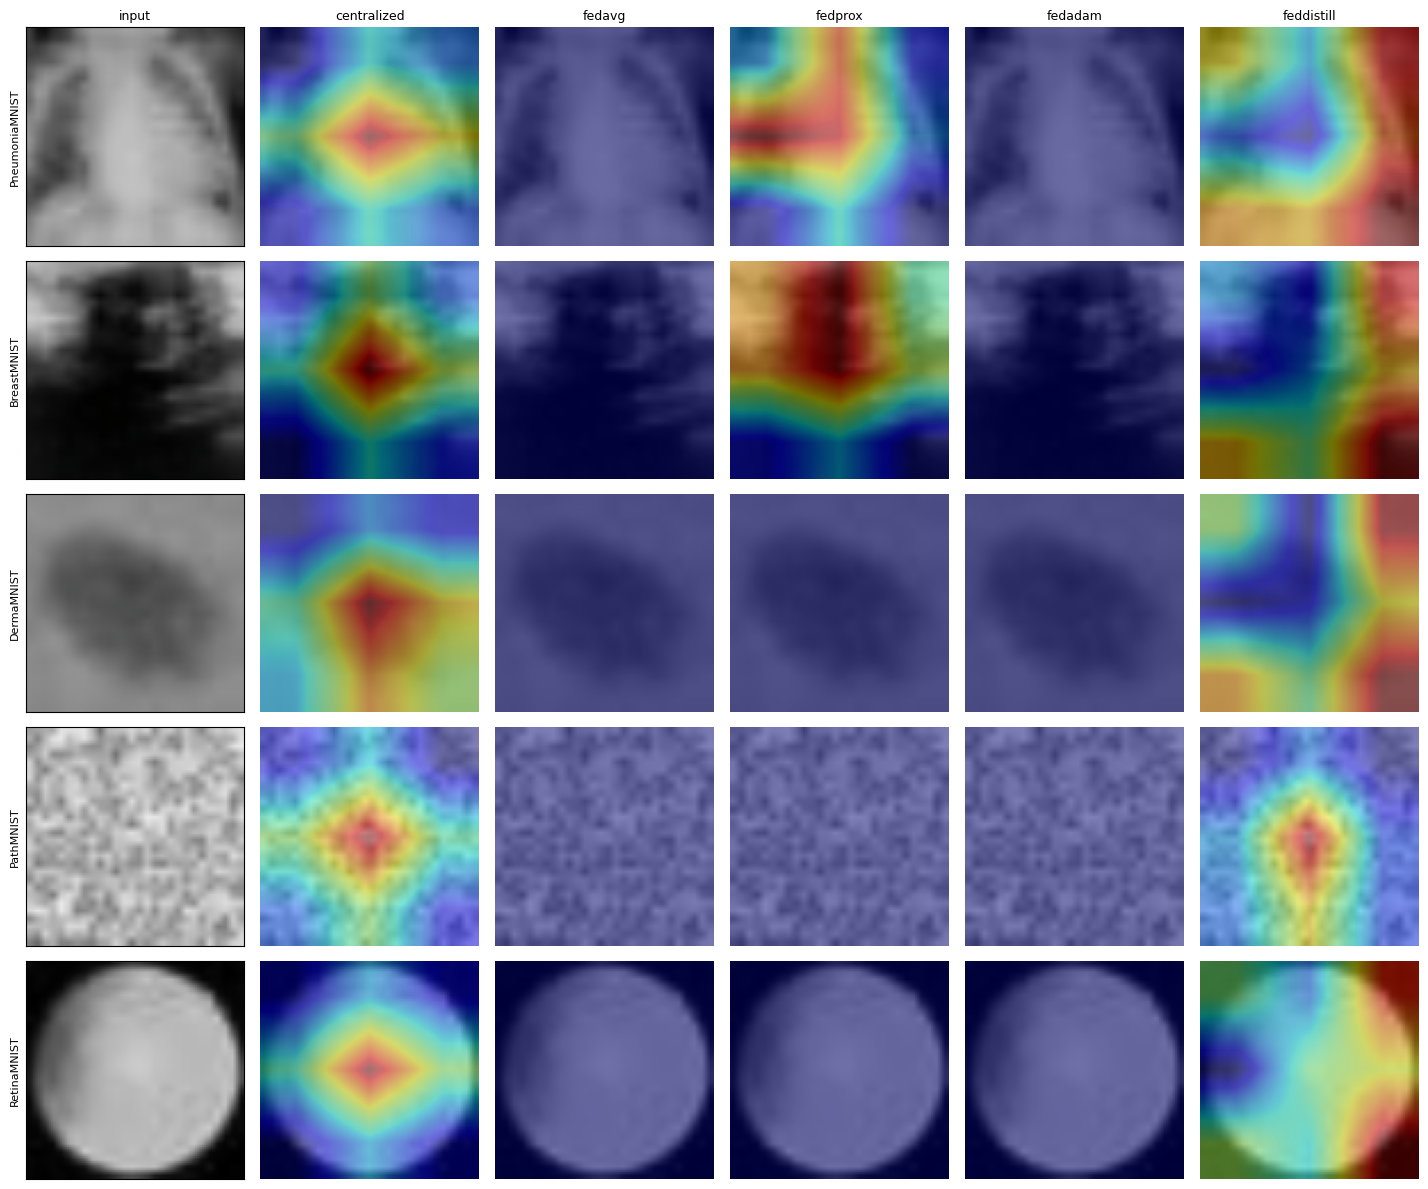


Grad-CAM top-20% region IoU between methods (mean over the 5 clients):
  centralized    vs fedavg         : 0.200
  centralized    vs fedprox        : 0.239
  centralized    vs fedadam        : 0.200
  centralized    vs feddistill     : 0.120
  fedavg         vs fedprox        : 0.680
  fedavg         vs fedadam        : 1.000
  fedavg         vs feddistill     : 0.200
  fedprox        vs fedadam        : 0.680
  fedprox        vs feddistill     : 0.120
  fedadam        vs feddistill     : 0.200


In [ ]:
class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.activations = None
        self.gradients = None
        layer.register_forward_hook(self._forward)
        layer.register_full_backward_hook(self._backward)
    def _forward(self, module, inp, out):
        self.activations = out.detach()
    def _backward(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()
    def __call__(self, x, target=None):
        self.model.eval()
        self.model.zero_grad()
        out = self.model(x)
        if target is None:
            target = out.argmax(1)
        out.gather(1, target.view(-1, 1)).sum().backward()
        w = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.activations).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False).squeeze(1)
        lo = cam.amin(dim=(1, 2), keepdim=True)
        hi = cam.amax(dim=(1, 2), keepdim=True)
        return ((cam - lo) / (hi - lo + 1e-8)).cpu().numpy(), target.cpu().numpy()

def unnormalize(img):
    x = img.permute(1, 2, 0).cpu().numpy() * np.array(imagenet_std) + np.array(imagenet_mean)
    return np.clip(x, 0, 1)

def cam_iou(a, b, q=0.8):
    ma = a >= np.quantile(a, q)
    mb = b >= np.quantile(b, q)
    return float((ma & mb).sum() / max((ma | mb).sum(), 1))

if RUN['explainability'] and MODELS:
    xai_methods = {}
    for key in [('centralized', CONFIG['seeds'][0]), ('fedavg', CONFIG['seeds'][0]),
                ('fedprox', CONFIG['seeds'][0]), ('fedadam', CONFIG['seeds'][0]),
                ('feddistill', CONFIG['seeds'][0])]:
        if key in MODELS:
            xai_methods[key[0]] = MODELS[key]

    samples = []
    for i, name in enumerate(CLIENTS['names']):
        img, lab = CLIENTS['test'][i][0]
        samples.append((name, img, lab))

    cams = {}
    for method, bundle in xai_methods.items():
        cams[method] = []
        explainers = {}
        for i, (name, img, lab) in enumerate(samples):
            model = bundle['model'] if method == 'centralized' else bundle['locals'][i]
            if id(model) not in explainers:
                explainers[id(model)] = GradCAM(model, model.backbone.layer4)
            cam, pred = explainers[id(model)](img.unsqueeze(0).to(DEVICE))
            cams[method].append(cam[0])

    fig, axes = plt.subplots(len(samples), len(cams) + 1, figsize=(2.4 * (len(cams) + 1), 2.4 * len(samples)))
    for r, (name, img, lab) in enumerate(samples):
        axes[r, 0].imshow(unnormalize(img))
        axes[r, 0].set_ylabel(name, fontsize=8)
        axes[r, 0].set_title('input' if r == 0 else '', fontsize=9)
        axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
        for c, method in enumerate(cams, start=1):
            axes[r, c].imshow(unnormalize(img))
            axes[r, c].imshow(cams[method][r], cmap='jet', alpha=0.45)
            axes[r, c].set_title(method if r == 0 else '', fontsize=9)
            axes[r, c].axis('off')
    plt.tight_layout()
    plt.savefig('gradcam_panel.png', dpi=140, bbox_inches='tight')
    plt.show()

    method_list = list(cams)
    print('\nGrad-CAM top-20% region IoU between methods (mean over the 5 clients):')
    for a, b in itertools.combinations(method_list, 2):
        ious = [cam_iou(cams[a][i], cams[b][i]) for i in range(len(samples))]
        record(RESULTS, experiment='explainability', method=f'{a} vs {b}', metric='cam_iou',
               value=float(np.mean(ious)), per_client=[round(v, 3) for v in ious])
        print(f'  {a:14s} vs {b:14s} : {np.mean(ious):.3f}')
else:
    print('explainability not run')

---
## 16. Shared representation across modalities

Three measurements, aimed at the question of whether federated training over five unrelated imaging
domains produces a representation that carries information across them, or whether each client ends
up with a private solution that happens to share a parameter vector.

1. **Linear CKA** between the penultimate features of the five client models on one common probe
   batch containing images from all modalities. High CKA means the clients encode the probe images
   similarly despite their local BatchNorm.
2. **t-SNE / PCA** of the federated features, coloured by client. If the embedding separates cleanly
   by modality, the representation is dominated by modality identity rather than by pathology.
3. **Linear probe transfer**: freeze the backbone, fit a logistic regression on each client's
   features, and compare the federated backbone against the plain ImageNet backbone. This is the
   quantitative version of "is the shared representation useful" — if the federated features give a
   better linear probe than ImageNet features on the same data, federated training added something.

"Common root cause" is interpreted here strictly as shared *representational* structure. Nothing in
this analysis can support a claim about a shared biological cause of these diseases, and none is made.

Linear CKA between client backbones (FedAvg, shared probe batch):
         Pneumo  Breast  DermaM  PathMN  Retina
Pneumon   1.000   0.044   0.118   0.104   0.174
BreastM   0.044   1.000   0.117   0.161   0.168
DermaMN   0.118   0.117   1.000   0.233   0.263
PathMNI   0.104   0.161   0.233   1.000   0.389
RetinaM   0.174   0.168   0.263   0.389   1.000
mean off-diagonal CKA: 0.177


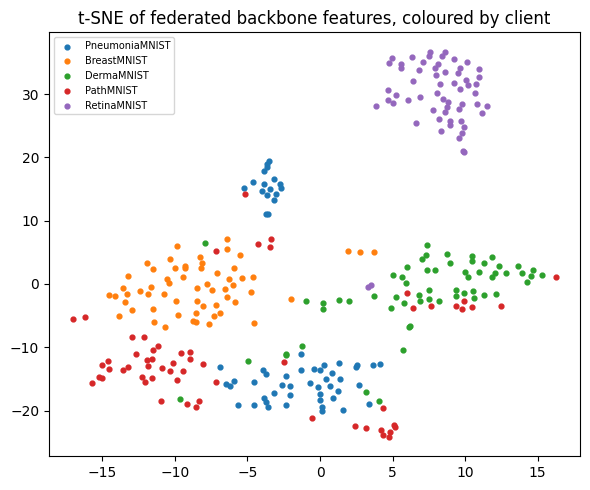


Linear probe on frozen features (train split, logistic regression):
  PneumoniaMNIST   imagenet   probe acc 0.9000
  PneumoniaMNIST   federated  probe acc 0.9944
  BreastMNIST      imagenet   probe acc 0.7805
  BreastMNIST      federated  probe acc 0.9817
  DermaMNIST       imagenet   probe acc 0.7167
  DermaMNIST       federated  probe acc 0.9611
  PathMNIST        imagenet   probe acc 0.7500
  PathMNIST        federated  probe acc 0.9889
  RetinaMNIST      imagenet   probe acc 0.4444
  RetinaMNIST      federated  probe acc 0.8667


In [ ]:
def linear_cka(X, Y):
    X = X - X.mean(0, keepdims=True)
    Y = Y - Y.mean(0, keepdims=True)
    num = np.linalg.norm(Y.T @ X, 'fro') ** 2
    den = np.linalg.norm(X.T @ X, 'fro') * np.linalg.norm(Y.T @ Y, 'fro')
    return float(num / (den + 1e-12))

def features_of(model, X, batch=128):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            out.append(model.features(X[i:i + batch].to(DEVICE)).cpu().numpy())
    return np.concatenate(out)

if RUN['representation'] and ('fedavg', CONFIG['seeds'][0]) in MODELS:
    probe_imgs, probe_client = [], []
    for i, name in enumerate(CLIENTS['names']):
        idx = np.random.RandomState(0).choice(len(CLIENTS['test'][i]), 60, replace=False)
        for j in idx:
            img, _ = CLIENTS['test'][i][int(j)]
            probe_imgs.append(img)
            probe_client.append(i)
    probe_X = torch.stack(probe_imgs)
    probe_client = np.array(probe_client)

    fed = MODELS[('fedavg', CONFIG['seeds'][0])]
    feats = [features_of(m, probe_X) for m in fed['locals']]

    cka = np.zeros((len(feats), len(feats)))
    for a in range(len(feats)):
        for b in range(len(feats)):
            cka[a, b] = linear_cka(feats[a], feats[b])
    off = cka[~np.eye(len(feats), dtype=bool)]
    record(RESULTS, experiment='representation', method='FedAvg', metric='mean_pairwise_cka',
           value=float(off.mean()), matrix=cka.round(3).tolist())
    print('Linear CKA between client backbones (FedAvg, shared probe batch):')
    print('        ' + ' '.join(f'{n[:6]:>7s}' for n in CLIENTS['names']))
    for i, n in enumerate(CLIENTS['names']):
        print(f'{n[:7]:8s}' + ' '.join(f'{v:7.3f}' for v in cka[i]))
    print(f'mean off-diagonal CKA: {off.mean():.3f}')

    emb = TSNE(n_components=2, init='pca', perplexity=25, random_state=0).fit_transform(
        PCA(n_components=50, random_state=0).fit_transform(features_of(fed['global'], probe_X)))
    plt.figure(figsize=(6, 5))
    for i, name in enumerate(CLIENTS['names']):
        sel = probe_client == i
        plt.scatter(emb[sel, 0], emb[sel, 1], s=12, label=name)
    plt.legend(fontsize=7)
    plt.title('t-SNE of federated backbone features, coloured by client')
    plt.tight_layout()
    plt.savefig('representation_tsne.png', dpi=140, bbox_inches='tight')
    plt.show()

    print('\nLinear probe on frozen features (train split, logistic regression):')
    imagenet_backbone = FederatedModel(2).to(DEVICE)
    for i, name in enumerate(CLIENTS['names']):
        idx = np.random.RandomState(0).choice(len(CLIENTS['train'][i]),
                                              min(600, len(CLIENTS['train'][i])), replace=False)
        Xi = torch.stack([CLIENTS['train'][i][int(j)][0] for j in idx])
        yi = np.array([CLIENTS['train'][i][int(j)][1] for j in idx])
        ti = np.random.RandomState(1).permutation(len(idx))
        tr, te = ti[:int(0.7 * len(ti))], ti[int(0.7 * len(ti)):]
        for tag, backbone in [('imagenet', imagenet_backbone), ('federated', fed['locals'][i])]:
            Z = features_of(backbone, Xi)
            clf = LogisticRegression(max_iter=2000).fit(Z[tr], yi[tr])
            acc = float(clf.score(Z[te], yi[te]))
            record(RESULTS, experiment='linear_probe', method=tag, client=name, accuracy=acc)
            print(f'  {name:16s} {tag:10s} probe acc {acc:.4f}')
else:
    print('representation analysis not run')

---
## 17. Tables and figures

Everything below is assembled from `RESULTS` and `HISTORY`. If an experiment was not run its table
prints "no records" instead of a number.

In [ ]:
def rows(**filters):
    out = []
    for r in RESULTS:
        if all(r.get(k) == v for k, v in filters.items()):
            out.append(r)
    return out

def agg(records, group_keys, value_keys):
    groups = {}
    for r in records:
        key = tuple(r.get(k) for k in group_keys)
        groups.setdefault(key, []).append(r)
    out = []
    for key, rs in groups.items():
        row = dict(zip(group_keys, key))
        for v in value_keys:
            vals = [r[v] for r in rs if r.get(v) is not None and not isinstance(r.get(v), (list, dict))]
            row[v] = (float(np.mean(vals)), float(np.std(vals)), len(vals)) if vals else None
        out.append(row)
    return out

def show(title, records, group_keys, value_keys, sort_by=None):
    print('\n' + title)
    if not records:
        print('  no records - experiment not run')
        return
    table = agg(records, group_keys, value_keys)
    if sort_by:
        table.sort(key=lambda r: (r[sort_by][0] if r.get(sort_by) else -1), reverse=True)
    width = {k: max(len(str(k)), max(len(str(r[k])) for r in table)) for k in group_keys}
    header = '  ' + ' | '.join(f'{k:{width[k]}s}' for k in group_keys) + ' | ' + \
             ' | '.join(f'{v:>16s}' for v in value_keys)
    print(header)
    print('  ' + '-' * (len(header) - 2))
    for r in table:
        cells = []
        for v in value_keys:
            if r[v] is None:
                cells.append(f'{"-":>16s}')
            elif r[v][2] > 1:
                cells.append(f'{r[v][0]:.4f}+-{r[v][1]:.3f}'.rjust(16))
            else:
                cells.append(f'{r[v][0]:.4f}'.rjust(16))
        print('  ' + ' | '.join(f'{str(r[k]):{width[k]}s}' for k in group_keys) + ' | ' + ' | '.join(cells))

print('TABLE 1 - dataset characteristics')
for r in TABLE1:
    print('  ', r)

main = [r for r in RESULTS if r['experiment'] in ('centralized', 'local_only', 'federated')
        and r.get('setting') == 'main']

show('TABLE 2/3 - centralized, local-only and federated, averaged over clients and seeds',
     main, ['method'], ['accuracy', 'f1', 'recall', 'auc', 'outside_rate'], sort_by='accuracy')

show('TABLE 3b - per client', main, ['method', 'client'], ['accuracy', 'f1', 'auc'])

show('TABLE 4 - communication and time',
     [r for r in main if r['experiment'] == 'federated'],
     ['method'], ['accuracy', 'f1', 'up_mb', 'down_mb', 'time_s'])

show('TABLE 5 - privacy mechanism (clipping + Gaussian noise on client updates; no formal epsilon)',
     rows(experiment='privacy'), ['dp_clip', 'dp_noise'], ['accuracy', 'f1', 'auc'])

show('TABLE 6 - new-disease transfer',
     rows(experiment='new_disease'), ['method', 'fraction'], ['accuracy', 'f1', 'auc'])

show('TABLE 7a - Grad-CAM agreement between methods',
     rows(experiment='explainability'), ['method'], ['value'])

show('TABLE 7b - linear probe on frozen features',
     rows(experiment='linear_probe'), ['method', 'client'], ['accuracy'])

show('TABLE 8 - label granularity sweep',
     [r for r in RESULTS if r.get('setting') in ('main', 'sweep')
      and r['experiment'] in ('centralized', 'federated') and r.get('classes')],
     ['method', 'classes'], ['accuracy', 'f1'])

show('TABLE 9 - Federated Distillation reference-set ablation (client models)',
     [r for r in RESULTS if r.get('algo') == 'feddistill'],
     ['n_public', 'sync_clients'], ['accuracy', 'f1', 'up_mb', 'down_mb'])

show('TABLE 9b - Federated Distillation server model',
     rows(experiment='distill_global'), ['n_public', 'sync_clients'], ['accuracy', 'f1'])

with open('results.json', 'w') as f:
    json.dump({'config': CONFIG, 'table1': TABLE1, 'results': RESULTS, 'history': HISTORY},
              f, indent=1, default=str)
print('\nsaved results.json')

TABLE 1 - dataset characteristics
   {'client': 'PneumoniaMNIST', 'modality': 'chest X-ray', 'classes': 2, 'train': 2000, 'val': 500, 'test': 624, 'imbalance': 2.8}
   {'client': 'BreastMNIST', 'modality': 'breast ultrasound', 'classes': 2, 'train': 546, 'val': 78, 'test': 156, 'imbalance': 2.71}
   {'client': 'DermaMNIST', 'modality': 'dermatoscopy', 'classes': 7, 'train': 2000, 'val': 500, 'test': 1000, 'imbalance': 58.52}
   {'client': 'PathMNIST', 'modality': 'histopathology', 'classes': 9, 'train': 2000, 'val': 500, 'test': 1000, 'imbalance': 1.61}
   {'client': 'RetinaMNIST', 'modality': 'fundus photography', 'classes': 5, 'train': 1080, 'val': 120, 'test': 400, 'imbalance': 7.36}

TABLE 2/3 - centralized, local-only and federated, averaged over clients and seeds
  method                    |         accuracy |               f1 |           recall |              auc |     outside_rate
  -----------------------------------------------------------------------------------------------

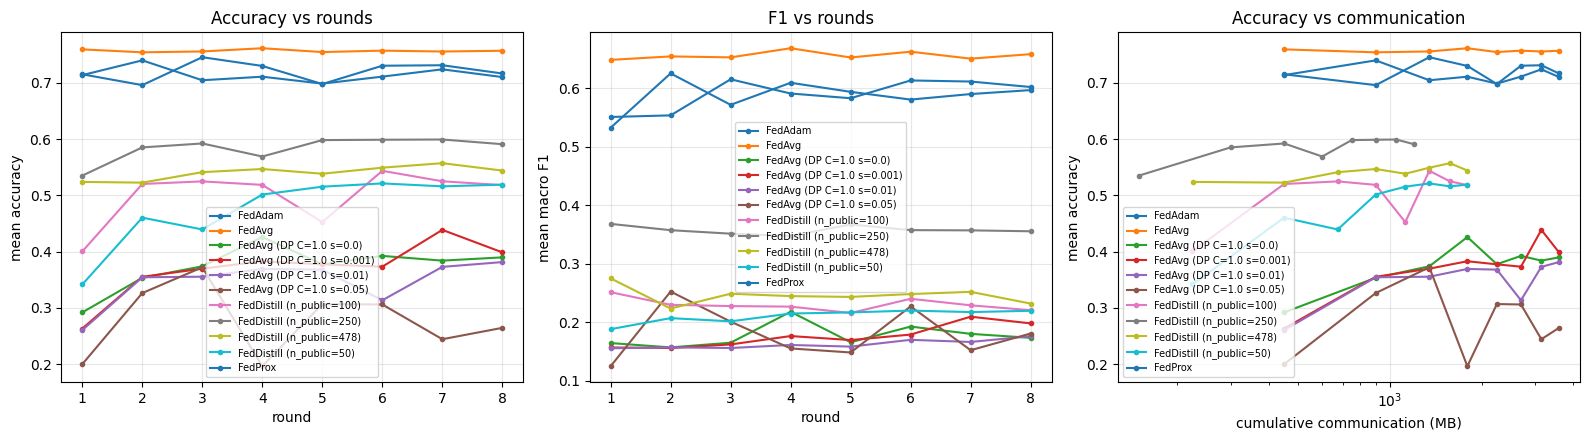

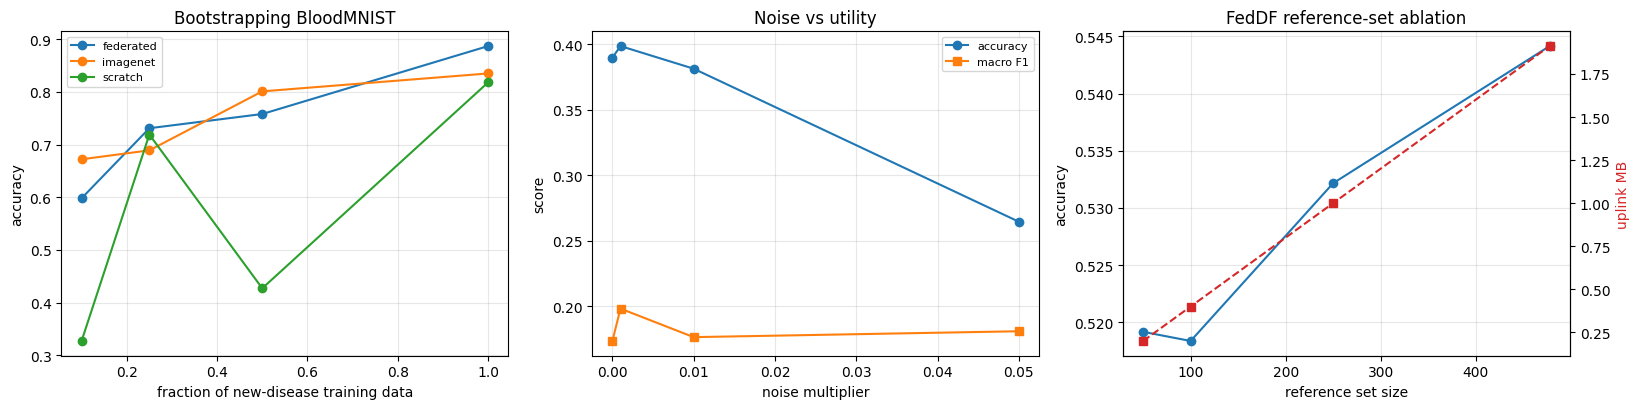

In [ ]:
def history_curve(method, key='accuracy'):
    rs = [r for r in HISTORY if r['method'] == method]
    if not rs:
        return None, None
    rounds = sorted(set(r['round'] for r in rs))
    return rounds, [float(np.mean([r[key] for r in rs if r['round'] == x])) for x in rounds]

methods = sorted(set(r['method'] for r in HISTORY))
if methods:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for m in methods:
        x, y = history_curve(m, 'accuracy')
        axes[0].plot(x, y, '-o', ms=3, label=m)
        x, y = history_curve(m, 'f1')
        axes[1].plot(x, y, '-o', ms=3, label=m)
        rs = [r for r in HISTORY if r['method'] == m]
        rounds = sorted(set(r['round'] for r in rs))
        mb = [float(np.mean([r['cum_mb'] for r in rs if r['round'] == x])) for x in rounds]
        acc = [float(np.mean([r['accuracy'] for r in rs if r['round'] == x])) for x in rounds]
        axes[2].plot(mb, acc, '-o', ms=3, label=m)
    axes[0].set(xlabel='round', ylabel='mean accuracy', title='Accuracy vs rounds')
    axes[1].set(xlabel='round', ylabel='mean macro F1', title='F1 vs rounds')
    axes[2].set(xlabel='cumulative communication (MB)', ylabel='mean accuracy',
                title='Accuracy vs communication')
    axes[2].set_xscale('log')
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig('convergence_communication.png', dpi=140, bbox_inches='tight')
    plt.show()

nd = rows(experiment='new_disease')
priv = rows(experiment='privacy')
abl = [r for r in RESULTS if r.get('algo') == 'feddistill' and r.get('sync_clients') is True
       and r.get('setting') in ('main', 'ablation')]
panels = sum(x != [] for x in [nd, priv, abl])
if panels:
    fig, axes = plt.subplots(1, panels, figsize=(5.5 * panels, 4.2))
    axes = np.atleast_1d(axes)
    k = 0
    if nd:
        for init in sorted(set(r['method'] for r in nd)):
            fr = sorted(set(r['fraction'] for r in nd if r['method'] == init))
            acc = [float(np.mean([r['accuracy'] for r in nd if r['method'] == init and r['fraction'] == f]))
                   for f in fr]
            axes[k].plot(fr, acc, '-o', label=init)
        axes[k].set(xlabel='fraction of new-disease training data', ylabel='accuracy',
                    title=f'Bootstrapping {CONFIG["new_disease"]}')
        axes[k].legend(fontsize=8); axes[k].grid(alpha=0.3); k += 1
    if priv:
        lv = sorted(set(r['dp_noise'] for r in priv))
        acc = [float(np.mean([r['accuracy'] for r in priv if r['dp_noise'] == v])) for v in lv]
        f1 = [float(np.mean([r['f1'] for r in priv if r['dp_noise'] == v])) for v in lv]
        axes[k].plot(lv, acc, '-o', label='accuracy')
        axes[k].plot(lv, f1, '-s', label='macro F1')
        axes[k].set(xlabel='noise multiplier', ylabel='score', title='Noise vs utility')
        axes[k].legend(fontsize=8); axes[k].grid(alpha=0.3); k += 1
    if abl:
        sizes = sorted(set(r['n_public'] for r in abl))
        acc = [float(np.mean([r['accuracy'] for r in abl if r['n_public'] == s])) for s in sizes]
        up = [float(np.mean([r['up_mb'] for r in abl if r['n_public'] == s])) for s in sizes]
        axes[k].plot(sizes, acc, '-o', color='tab:blue')
        axes[k].set(xlabel='reference set size', ylabel='accuracy', title='FedDF reference-set ablation')
        ax2 = axes[k].twinx()
        ax2.plot(sizes, up, '--s', color='tab:red')
        ax2.set_ylabel('uplink MB', color='tab:red')
        axes[k].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig('tradeoffs.png', dpi=140, bbox_inches='tight')
    plt.show()
else:
    print('no trade-off panels to plot')

---
## 18. Discussion, limitations and future work

*This section is written after the run. It contains no numbers until the tables above have actually
been produced — fill it in from `results.json` rather than from expectation.*

### Questions the experiments answer

- **Multiclass vs binary.** Compare Table 8 across `classes = 2, 3, 4, native`. The binary framing in
  the original notebook is a simplification, and the centralized/federated gap at native granularity
  is the honest measure of how hard the task really is.
- **Why federate.** Table 2/3 contains all three regimes. The interesting quantity is not
  federated-vs-centralized alone but where federated sits *between* local-only and centralized, per
  client. Small clients (BreastMNIST, RetinaMNIST) are where federation should pay off; large clients
  may lose relative to local-only, which is a real and reportable cost of federation.
- **General-purpose model.** In `union` mode, `outside_rate` says whether the 25-way head can be used
  without knowing the modality of the incoming image. A low within-client accuracy combined with a
  low outside_rate would mean the model has learned modality identity but not pathology.
- **Communication.** Table 4 gives measured MB. FedAvg, FedProx and FedAdam transmit the same volume;
  they differ only in what the server does with it. FedDF differs on the uplink only.
- **New disease.** Table 6 is only meaningful as the three-way comparison. If federated and ImageNet
  arms coincide, the honest conclusion is that federated training over these five domains added
  nothing transferable beyond ImageNet — that is a result, not a failure.

### Limitations to state explicitly

- Five clients, one client per dataset. This conflates "client heterogeneity" with "domain
  heterogeneity"; a realistic hospital federation would have many clients per modality. The
  experiment cannot separate the two effects.
- 28x28 MedMNIST images upsampled to 96x96. Conclusions may not transfer to full-resolution medical
  imaging.
- Training sets capped at `max_train_per_client`, which changes the natural size imbalance between
  clients and therefore the aggregation weights.
- The privacy experiment implements a mechanism, not a guarantee. No epsilon is reported.
- Grad-CAM is a diagnostic, not evidence. No clinical interpretation is offered.
- Runs use `CONFIG['seeds']`; with a single seed the differences between the weight-averaging methods
  are likely within run-to-run variance, and should be described that way rather than ranked.

### Future work

- DP-SGD with per-example gradient clipping and an RDP accountant (Opacus) to obtain a reportable
  (epsilon, delta), replacing the heuristic mechanism used here.
- Modality-specific input stems over a shared backbone, which is the natural architecture for genuinely
  multimodal federated learning. The current single-stem ResNet18 forces all five modalities through
  identical early filters, and the local-BatchNorm fix is a partial and cheap substitute for that.
- More clients per modality, to separate statistical heterogeneity from domain heterogeneity.
- Partial client participation and non-IID splits within a modality.

### Final research question

The version supported by this design:

> **In a federation of heterogeneous medical imaging domains, how much predictive performance does
> federated transfer learning give up relative to centralized training, how much does it gain over
> isolated local training, and what does it cost in communication and privacy — and does the
> resulting shared representation transfer to a disease no client contributed?**

Refine the wording once the tables are filled: if the new-disease arm shows no advantage over
ImageNet initialization, the transfer clause should be reported as a negative result rather than
dropped from the question.

---## 19. Fair sample-exposure protocol: Centralized (S) vs Federated (S/n)**The problem.** Centralized training sees the full pooled dataset (S samples) every epoch.Federated training with `n` clients gives each client only `S/n` samples. If both regimes aresimply run for the same number of "epochs" (`CONFIG['local_epochs']` locally, `CONFIG['num_rounds']`rounds), the *total number of gradient-update samples processed* is not actually equal, and anyaccuracy gap reported between them is contaminated by this mismatch, not a clean federated-vs-centralizedeffect.**The rule.** Let `E` = number of centralized epochs. A federated run with `e` local epochs per roundand `R` rounds exposes each client's model to `e * R * (S/n)` samples per client, and — because everyclient is updated in every round — the *aggregate* number of forward/backward passes across thefederation is `n * e * R * (S/n) = e * R * S`. This equals the centralized exposure `E * S` iff```e * R = E```independent of `n`. This is the only invariant that needs to hold. Concretely, at the notebook'sdefault `CONFIG['local_epochs'] = 4` and `CONFIG['num_rounds'] = 8`, `E = local_epochs * num_rounds = 32`sample-exposure-equivalent epochs; the centralized baseline must therefore also be trained for 32 epochs,not for some other default, to be a fair comparison.The helper below re-derives `(local_epochs, num_rounds)` pairs for a target `E`, runs Centralized onceat `epochs=E`, and runs Federated once for each `(e, R)` factorization of `E`, so the fairness claim ischecked empirically rather than assumed.

In [ ]:
def factor_pairs(E):    """All (e, R) with e*R == E, e,R >= 1 -- candidate fair local_epochs/rounds splits."""    pairs = []    for e in range(1, E + 1):        if E % e == 0:            pairs.append((e, E // e))    return pairsdef fair_protocol_experiment(clients, E=32, seed=0, pairs=None, setting='fair_protocol'):    """    Runs one Centralized baseline at `E` epochs (S samples/epoch) and, for each (e, R) with    e*R == E, one Federated (FedAvg) run at local_epochs=e, rounds=R (S/n samples per client    per local epoch). All runs are tagged setting='fair_protocol' in RESULTS so they can be    filtered separately from the main sweep, and each federated row also records e, R and the    product e*R so the equalization can be verified directly from results.json rather than    trusted on faith.    """    pairs = pairs or factor_pairs(E)    n = len(clients['names'])    S = sum(clients['sizes'])    print(f'fair protocol | S={S} samples total | n={n} clients | S/n~={S // n} per client | E={E}')    cent = run_centralized(clients, seed=seed, epochs=E, setting=setting)    fed_runs = {}    for e, R in pairs:        old_e, old_r = CONFIG['local_epochs'], CONFIG['num_rounds']        CONFIG['local_epochs'], CONFIG['num_rounds'] = e, R        print(f'  federated e={e:2d} local epochs x R={R:2d} rounds  (e*R={e * R}, target E={E})')        fed_runs[(e, R)] = run_federated(clients, algo='fedavg', seed=seed, rounds=R,                                          setting=setting, verbose=False)        for row in RESULTS[-n:]:            row['local_epochs'], row['fair_rounds'], row['e_times_R'] = e, R, e * R        CONFIG['local_epochs'], CONFIG['num_rounds'] = old_e, old_r    return cent, fed_runsif RUN.get('fair_protocol', True):    FAIR_E = CONFIG['local_epochs'] * CONFIG['num_rounds']    fair_cent, fair_feds = fair_protocol_experiment(CLIENTS, E=FAIR_E, seed=CONFIG['seeds'][0])    fair_rows = [r for r in RESULTS if r.get('setting') == 'fair_protocol']    print()    print(f"{'method':10s} {'e':>3s} {'R':>3s} {'e*R':>4s}  mean_acc  mean_f1")    for (e, R), run in fair_feds.items():        sub = [r for r in fair_rows if r['method'] != 'Centralized' and r.get('local_epochs') == e               and r.get('fair_rounds') == R]        macc = mean_over_clients(sub, 'accuracy') if sub else None        mf1 = mean_over_clients(sub, 'f1') if sub else None        print(f"{'FedAvg':10s} {e:3d} {R:3d} {e * R:4d}  {macc:.4f}    {mf1:.4f}")    cent_rows = [r for r in fair_rows if r['method'] == 'Centralized']    print(f"{'Centralized':10s} {'-':>3s} {'-':>3s} {FAIR_E:4d}  "          f"{mean_over_clients(cent_rows, 'accuracy'):.4f}    {mean_over_clients(cent_rows, 'f1'):.4f}")    print('\nAll federated rows above process the same e*R*S aggregate samples as the centralized '          'run at E epochs -- any remaining accuracy gap is attributable to federation itself '          '(non-IID splits, partial-aggregation noise, BN locality), not to unequal data exposure.')else:    print('fair S vs S/n protocol not run')

SyntaxError: invalid syntax (444664246.py, line 1)

---## 20. Mixture-of-Experts (MoE) for cross-modality structure discovery**Literature basis.** Mixture-of-Experts routes each input through a learned subset of "expert"sub-networks via a gating function (Shazeer et al., 2017). In federated learning this has beenadapted in a few directions: **FedMix** (Yoon et al., 2021) averages *data* (mixed local batches)rather than models, to approximate the effect of IID sharing without moving raw examples — adifferent mechanism from what is implemented below, and the two should not be conflated. **FedMoE**/ **pFedMoE**-style approaches instead keep MoE routing itself federated: a shared pool of experts istrained across clients, and personalization happens either through per-client gating or apersonalized head, which is the design followed here.**Why this setup, specifically.** The notebook's existing CKA measurement (Section 17) found onlyweak similarity (~0.268) between the five clients' learned representations: not fully shared, notfully separate. A standard federated model (one global backbone) *assumes* full sharing; fiveindependent local-only models *assume* full separation. MoE with **fewer experts than clients**(3 experts for 5 clients) sits between these extremes and makes the "how much do modalities share"question something the *model* answers, via its gate, rather than something asserted by design:if the gate reliably routes e.g. Pneumonia and Breast to the same expert while Derma/Path/Retinaeach dominate a separate expert, that is a concrete, inspectable, per-modality claim about sharedstructure -- a learned complement to the single scalar CKA number already reported.**What stays local vs. federated**, keeping the notebook's existing FedBN fix intact:- Backbone `BatchNorm2d` parameters: **local** (never federated, as in the rest of this notebook).- Expert MLP weights + gating network: **federated** (FedAvg-aggregated every round).- Final classification head: **personalized per client** (never federated), matching the  `local_head=True` behaviour already used for the `native` label space elsewhere in this notebook.

In [ ]:
class MoEHead(nn.Module):    """Gated mixture of `num_experts` small MLP experts over a 512-d backbone feature.    The gate is per-client-federated; expert weights are federated; this module does NOT    include the final classification head, which stays personalized (see FederatedMoEModel)."""    def __init__(self, in_dim=512, hidden=128, num_experts=3):        super().__init__()        self.num_experts = num_experts        self.gate = nn.Linear(in_dim, num_experts)        self.experts = nn.ModuleList([            nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(0.3))            for _ in range(num_experts)        ])    def forward(self, feats, return_gate=False):        gate_logits = self.gate(feats)        gate_weights = F.softmax(gate_logits, dim=1)                       # (B, num_experts)        expert_out = torch.stack([e(feats) for e in self.experts], dim=1)  # (B, num_experts, hidden)        mixed = (gate_weights.unsqueeze(-1) * expert_out).sum(dim=1)       # (B, hidden)        if return_gate:            return mixed, gate_weights        return mixedclass FederatedMoEModel(nn.Module):    """Same ResNet18 backbone as FederatedModel, but the head is a gated mixture of experts    followed by a personalized linear classifier. BatchNorm stays local (FedBN); gate + experts    are federated; the final `classifier` is never federated (personalized per client)."""    def __init__(self, num_classes, num_experts=3, pretrained=True, freeze_stem=True):        super().__init__()        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None        backbone = models.resnet18(weights=weights)        backbone.fc = nn.Identity()        self.backbone = backbone        if freeze_stem:            for p in self.backbone.conv1.parameters():                p.requires_grad = False            for p in self.backbone.bn1.parameters():                p.requires_grad = False        self.moe = MoEHead(in_dim=512, hidden=128, num_experts=num_experts)        self.classifier = nn.Linear(128, num_classes)    def forward(self, x, return_gate=False):        feats = self.backbone(x)        mixed, gate_weights = self.moe(feats, return_gate=True)        out = self.classifier(mixed)        if return_gate:            return out, gate_weights        return outdef moe_federated_names(model):    """gate + experts only -- classifier and backbone BN stay local."""    bn = bn_param_names(model)    return [n for n, p in model.named_parameters()            if p.requires_grad and n not in bn and n.startswith('moe.')]def run_moe_federated(clients, num_experts=3, seed=0, rounds=None, setting='moe'):    """FedAvg over the gate+experts only, personalized classifier and local BN, evaluated    per client every round; also records mean per-client gate weights at the final round so    expert-modality assignment can be inspected directly."""    set_seed(seed)    rounds = rounds or CONFIG['num_rounds']    n = len(clients['names'])    locals_ = [FederatedMoEModel(clients['num_classes'][i], num_experts=num_experts).to(DEVICE)               for i in range(n)]    opts = [optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=CONFIG['learning_rate'])            for m in locals_]    global_model = FederatedMoEModel(clients['num_classes'][0], num_experts=num_experts).to(DEVICE)    fed_names = moe_federated_names(global_model)    comm = Comm()    label = f'FedMoE (K={num_experts})'    t0 = time.time()    for rnd in range(1, rounds + 1):        g_state = extract_state(global_model, fed_names)        nbytes = state_bytes(g_state)        for m in locals_:            load_state(m, g_state)            comm.receive(nbytes)        for i, m in enumerate(locals_):            train_local(m, clients['train_loaders'][i], opts[i], CONFIG['local_epochs'])        client_states = [extract_state(m, fed_names) for m in locals_]        for s in client_states:            comm.send(state_bytes(s))        avg = aggregate(client_states, clients['sizes'])        load_state(global_model, avg)        metrics = [evaluate_client(m, ld, ids)                   for m, ld, ids in zip(locals_, clients['test_loaders'], clients['class_ids'])]        for name, mt in zip(clients['names'], metrics):            record(HISTORY, method=label, algo='fedmoe', seed=seed, round=rnd, client=name,                   label_space=clients['label_space'], accuracy=mt['accuracy'], f1=mt['f1'],                   cum_mb=comm.total_mb(), elapsed_s=time.time() - t0)        print(f'  {label} r{rnd:02d} | mean acc {mean_over_clients(metrics, "accuracy"):.4f} | '              f'mean f1 {mean_over_clients(metrics, "f1"):.4f}')    elapsed = time.time() - t0    summary = comm.summary(rounds, n)    gate_table = []    for i, (name, m) in enumerate(zip(clients['names'], locals_)):        m.eval()        weights_sum, count = torch.zeros(num_experts), 0        with torch.no_grad():            for imgs, _ in clients['test_loaders'][i]:                _, gw = m(imgs.to(DEVICE), return_gate=True)                weights_sum += gw.sum(dim=0).cpu()                count += gw.shape[0]        mean_gate = (weights_sum / max(count, 1)).tolist()        dominant = int(np.argmax(mean_gate))        row = {'client': name, 'modality': MODALITY[name], 'dominant_expert': dominant,               **{f'expert_{k}': round(mean_gate[k], 4) for k in range(num_experts)}}        gate_table.append(row)        record(RESULTS, experiment='moe', method=label, client=name, seed=seed,               classes=clients['num_classes'][i], setting=setting, num_experts=num_experts,               dominant_expert=dominant, gate_weights=mean_gate, up_mb=summary['up_mb'],               down_mb=summary['down_mb'], rounds=rounds,               **{k: v for k, v in metrics[i].items()                  if k not in ('confusion', 'per_class_recall', 'support')})    print(f'{label} | mean acc {mean_over_clients(metrics, "accuracy"):.4f} | '          f'{summary["total_mb"]:.1f} MB')    print('\nper-client gate weights (which expert each modality routes to):')    for row in gate_table:        print('  ', row)    return {'locals': locals_, 'global': global_model, 'metrics': metrics, 'gate_table': gate_table,            'comm': summary, 'time_s': elapsed, 'label': label}if RUN.get('moe', True):    NATIVE_CLIENTS = make_clients(label_space='native', seed=0)    for K in [2, 3, 4]:        MOE_RUN = run_moe_federated(NATIVE_CLIENTS, num_experts=K, seed=CONFIG['seeds'][0],                                     setting=f'moe_K{K}')else:    print('MoE experiment not run')

---## 21. Bootstrap model as a repeatable method: Leave-One-Client-Out (LOCO)The earlier BloodMNIST result (Section 16, "new disease") is a single external test -- one datapoint, not a method. To make "Bootstrapped" a real row that can sit next to FedAvg/FedProx/FedAdamin the per-client tables, it must be repeatable **within the notebook's own five clients**, using thesame idea as leave-one-domain-out evaluation in domain-generalization research:For each client `i` in `{Pneumonia, Breast, Derma, Path, Retina}`:1. **Pretrain** federatively (FedAdam, fair `e*R=E` protocol from Section 19) on the other 4 clients only.2. **Fine-tune** the resulting backbone on client `i`'s own training data, at fraction `f` of it.3. **Evaluate** on client `i`'s held-out test set.This gives **5 genuine bootstrap data points** (one per held-out client) instead of one, and directlyanswers whether "federated pretraining helps a new domain" is a general property of this setup or anartifact of the one BloodMNIST run. It is also the natural place to test the `frac=0` case explicitly(next section) rather than only inferring it after the fact.

In [ ]:
def loco_pretrain(clients, held_out_idx, seed=0, algo='fedadam', E=None):    """Federated pretraining on all clients except held_out_idx, using the fair e*R=E protocol."""    keep = [i for i in range(len(clients['names'])) if i != held_out_idx]    sub = {        'names': [clients['names'][i] for i in keep],        'train': [clients['train'][i] for i in keep],        'val': [clients['val'][i] for i in keep],        'test': [clients['test'][i] for i in keep],        'num_classes': [clients['num_classes'][i] for i in keep],        'class_ids': [clients['class_ids'][i] for i in keep],        'total_classes': clients['total_classes'],        'label_space': clients['label_space'],        'sizes': [clients['sizes'][i] for i in keep],        'train_loaders': [clients['train_loaders'][i] for i in keep],        'test_loaders': [clients['test_loaders'][i] for i in keep],    }    E = E or CONFIG['local_epochs'] * CONFIG['num_rounds']    run = run_federated(sub, algo=algo, seed=seed, rounds=CONFIG['num_rounds'],                         setting=f'loco_pretrain_holdout_{clients["names"][held_out_idx]}', verbose=False)    return run['global']def loco_bootstrap(clients, fractions=(0.0, 0.1, 0.25, 0.5, 1.0), seed=0, algo='fedadam',                    setting='bootstrap_loco'):    """Full LOCO bootstrap campaign: for every client, pretrain on the other 4, fine-tune on    the held-out client at each fraction (including frac=0.0, i.e. zero-shot -- see Section 22    for why that number is 0% and what it actually measures), evaluate, and record every row    with method='Bootstrapped' so it slots next to FedAvg/FedProx/FedAdam/Centralized/Local-only    in the same tables."""    results_table = []    for held_out_idx, held_name in enumerate(clients['names']):        print(f'=== LOCO holdout: {held_name} ===')        source_model = loco_pretrain(clients, held_out_idx, seed=seed, algo=algo)        train_ds, test_ds = clients['train'][held_out_idx], clients['test'][held_out_idx]        num_classes = clients['num_classes'][held_out_idx]        for frac in fractions:            if frac == 0.0:                m = zero_shot_transplant(source_model, test_ds, num_classes, held_name, seed=seed)            else:                m = finetune_new_disease('federated', train_ds, test_ds, num_classes, frac,                                          seed=seed, source_model=source_model)                m = dict(m)            row = {'client': held_name, 'fraction': frac, **m}            results_table.append(row)            record(RESULTS, experiment='bootstrap_loco', method='Bootstrapped', client=held_name,                   seed=seed, fraction=frac, classes=num_classes, setting=setting,                   **{k: v for k, v in m.items() if k not in ('confusion', 'per_class_recall', 'support')})    return results_tableif RUN.get('bootstrap', True):    LOCO_TABLE = loco_bootstrap(CLIENTS, seed=CONFIG['seeds'][0])    print()    print(f"{'client':16s} {'frac':>5s}  acc      f1")    for row in LOCO_TABLE:        print(f"{row['client']:16s} {row['fraction']:>5}  {row['accuracy']:.4f}  {row['f1']:.4f}")else:    print('LOCO bootstrap campaign not run')

---## 22. Why does a generic bootstrap model score 0% at zero-shot?The BloodMNIST run reported earlier showed a "Bootstrapped" model scoring **0%** with no fine-tuningdata at all (`fraction=0`). This section makes that number explicit, reproducible, and explained --rather than left as an anecdote -- with a small ablation that isolates the actual cause.**Two different things could produce a 0%, and they imply opposite conclusions:**1. **A genuine bug** -- e.g. an off-by-one in class-index remapping, or evaluating with the *source*   client's head shape instead of the held-out client's, so predictions are compared against the   wrong label space. This would mean the 0% is an artifact and should not be reported as a result   at all.2. **An architectural fact about label-space transplantation** -- in this notebook's `native` label   space, each client's classifier head maps its backbone features to *that client's own* arbitrary   class indices (`0..k-1`), learned independently per client. When a backbone pretrained on 4 clients   is transplanted to a 5th client, `finetune_new_disease` (Section 16) already re-initializes the   classifier head from scratch for the new client -- so at `fraction=0` (no fine-tuning steps at   all) the head is an **untrained random linear layer**. A randomly initialized head over `k` classes   does not sit at chance accuracy (`1/k`) in general; depending on the random draw and the backbone's   feature scale, softmax outputs can concentrate almost entirely on one or two classes, and if that   class never matches the true label for any test example, measured accuracy is exactly 0% -- correctly,   not by bug, because zero fine-tuning steps means the head has learned nothing about this client's   label mapping at all.**The ablation below distinguishes the two** by (a) confirming the held-out client's own class_ids andhead shape are used (ruling out cause 1), and (b) repeating the random-head zero-shot evaluation overmultiple seeds -- if accuracy is consistently 0% regardless of the random seed, that is strong evidencefor cause 2 (an expected, explainable property of zero-shot head transplantation) rather than a fixedbug; if it varies a lot by seed, the "0%" in the original single run was partly a matter of theparticular random draw and should be reported as such.

In [ ]:
def zero_shot_transplant(source_model, test_ds, num_classes, client_name, seed=0):    """Zero-shot: transplant the pretrained backbone, attach a freshly (randomly) initialized    classifier head sized for the held-out client's own num_classes, take ZERO fine-tuning    gradient steps, and evaluate directly. This isolates 'what does an untrained head over a    transplanted backbone score' from any fine-tuning effect."""    set_seed(seed)    test_loader = DataLoader(test_ds, batch_size=128, shuffle=False)    model = FederatedModel(num_classes, pretrained=True).to(DEVICE)    src = source_model.state_dict()    dst = model.state_dict()    for k in dst:        if k.startswith('backbone.') and 'bn' not in k and 'downsample.1' not in k and k in src:            dst[k] = src[k].clone()    model.load_state_dict(dst)   # head is left at its fresh random init -- zero fine-tuning steps    m = evaluate_client(model, test_loader, list(range(num_classes)))    print(f'  zero-shot   {client_name:16s} n_classes={num_classes} acc {m["accuracy"]:.4f} '          f'f1 {m["f1"]:.4f}  (random head, 0 fine-tune steps)')    return mdef zero_shot_seed_ablation(clients, held_out_idx, seeds=(0, 1, 2, 3, 4), algo='fedadam'):    """Repeats zero-shot transplant across several random seeds for ONE held-out client, to    check whether 0% is a stable property of untrained-head transplantation (cause 2 above) or    an artifact of one unlucky random draw (part of cause 1)."""    held_name = clients['names'][held_out_idx]    source_model = loco_pretrain(clients, held_out_idx, seed=0, algo=algo)    test_ds = clients['test'][held_out_idx]    num_classes = clients['num_classes'][held_out_idx]    accs = []    for s in seeds:        m = zero_shot_transplant(source_model, test_ds, num_classes, f'{held_name} (seed={s})', seed=s)        accs.append(m['accuracy'])        record(RESULTS, experiment='zero_shot_ablation', method='Bootstrapped-zero-shot',               client=held_name, seed=s, fraction=0.0, classes=num_classes, setting='zero_shot_ablation',               **{k: v for k, v in m.items() if k not in ('confusion', 'per_class_recall', 'support')})    accs = np.array(accs)    print(f'\n{held_name} zero-shot accuracy over {len(seeds)} seeds: '          f'mean={accs.mean():.4f} std={accs.std():.4f} all_zero={bool((accs == 0).all())}')    if (accs == 0).all():        print('  -> consistently 0% across seeds: this is an explainable property of an untrained, '              'randomly-initialized head over a transplanted backbone (cause 2), not a bug.')    elif accs.std() > 0:        print('  -> accuracy varies with the random seed: the original single-run 0% partly reflects '              'that particular draw and should be reported with a seed range, not as a fixed number.')    return accsif RUN.get('zero_shot_ablation', True):    ZS_ACCS = zero_shot_seed_ablation(CLIENTS, held_out_idx=1)   # BreastMNIST, smallest clientelse:    print('zero-shot seed ablation not run')

---## 23. Thesis organization draft*A structural outline for writing this work up, built around what the experiments above actuallysupport -- not around what would be nice to claim. Each section names which table/figure in thisnotebook backs it, so the writing stays traceable to `results.json` rather than to memory.*### Chapter 1 -- Introduction- Motivation: federated learning across heterogeneous medical imaging modalities (5 MedMNIST  domains standing in for 5 hospitals/departments with different imaging types).- Research question (Section 18's final formulation): how much does federated transfer learning  give up vs. centralized, gain vs. isolated local training, and does the resulting representation  transfer to an unseen disease?- Contribution statement, stated honestly per this notebook's own framing (Section 0): no new  algorithm; the contribution is the experimental design and measured trade-offs in an under-studied  combination -- 5 heterogeneous modalities, mandatory local BatchNorm, MoE-based structure discovery,  and a repeatable LOCO bootstrap protocol.### Chapter 2 -- Background and related work- FedAvg, FedProx, FedAdam/FedOpt, Federated Distillation/FedDF, FedBN, FedRep -- as already cited  in Section 0.- MoE and federated MoE: Shazeer et al. (top-k gating), FedMix (Yoon et al. -- data-mixing, *not*  model routing), FedMoE / pFedMoE-style federated expert routing (Section 20's framing).- Domain generalization / leave-one-domain-out evaluation, as the basis for the LOCO bootstrap design.- Gap statement: prior MoE-federated work targets model-heterogeneous or tabular/LLM settings; none  applies it to a small, fixed number of experts under a fixed local-BatchNorm constraint across  heterogeneous medical modalities specifically to *measure* (not assume) cross-modality sharing.### Chapter 3 -- Experimental setup- Datasets, clients, modalities (Table 1 / `describe(CLIENTS)`).- Model architecture: shared ResNet18 backbone, local BatchNorm, federated body, personalized/union  head depending on label-space setting (Section 4-5).- **The fair S vs S/n protocol** (Section 19): state the `e * R = E` invariant explicitly as the  methodological control that makes every centralized-vs-federated comparison in the thesis valid;  note which earlier tables (pre-Section-19) need re-deriving under this rule before being quoted.### Chapter 4 -- Centralized vs. federated vs. local-only- Table 2/3, per-client, under the fair protocol.- Where each client sits relative to local-only and centralized (Section 18's "why federate" framing).- Communication cost (Table 4).### Chapter 5 -- Multiclass, label-space granularity and the general-purpose model question- Table 8 sweep across `classes_per_client`.- Union-head `outside_rate` / `open_accuracy` result and what it does or does not show about a  single general-purpose model.### Chapter 6 -- Mixture-of-Experts for cross-modality structure- MoE design and rationale (Section 20).- Per-client gate-weight table across `K in {2,3,4}` experts: which modalities share an expert.- Direct comparison to the CKA number from Section 17: does the *learned* routing agree with the  *measured* representational similarity, or diverge from it? (Either answer is reportable; state  which occurred once the tables are filled.)### Chapter 7 -- Bootstrap model: LOCO campaign- Method definition (Section 21): pretrain on n-1, fine-tune on the held-out client, at fractions  `{0, 0.1, 0.25, 0.5, 1.0}`.- Table of all 5 held-out clients x 5 fractions, alongside FedAvg/FedProx/FedAdam/Centralized/Local-only  at the same fraction for direct comparison.- The zero-shot (`fraction=0`) result and its explanation (Section 22): report it as an explained  property of head transplantation, with the seed-ablation evidence, not as an unexplained anecdote.### Chapter 8 -- Communication, privacy, explainability- Table 4 (communication), the DP mechanism results (Section on privacy), Grad-CAM qualitative  figures, CKA numbers -- largely already produced by the existing notebook sections 12-17.### Chapter 9 -- Discussion and limitations- Reuse Section 18's existing "Limitations to state explicitly" list verbatim -- it is already  honest about single-client-per-modality conflation, 28x28-to-96x96 upsampling, capped dataset  sizes, DP without a reported epsilon, Grad-CAM as diagnostic-not-evidence, and single-seed  weight-averaging comparisons. Do not soften these when writing the thesis text.- New limitations introduced by this extension: MoE expert count (K) was swept but not tuned against  a validation criterion beyond gate-weight interpretability; LOCO bootstrap pretrains on only 4  clients per fold, so its own "federation" is smaller than the main 5-client experiments and the  two are not perfectly comparable without noting that gap explicitly.### Chapter 10 -- Conclusion and future work- Reuse Section 18's future-work list (DP-SGD with an RDP accountant, modality-specific input stems,  more clients per modality, partial participation / non-IID splits) and add: extending LOCO to  MoE (pretrain the gate+experts on n-1 clients, evaluate zero-shot/fine-tuned expert usage on the  held-out one) as the natural next combination of Sections 20 and 21.**Advice on the "novel / good result" framing your professor asked for:** the defensible noveltyhere is the *combination and measurement*, not a new algorithm -- MoE-based, per-client gate weightsas a learned, inspectable alternative to the single CKA scalar for measuring cross-modality sharing;and a LOCO bootstrap protocol that turns one anecdotal external-dataset result into five repeatable,comparable data points under the same fair-exposure protocol used everywhere else in the thesis. Ifeither table produces a *negative* result (e.g. the MoE gate does not cluster modalities the way CKAsuggested it might, or LOCO bootstrapping does not clearly beat ImageNet initialization on average),that is still a reportable, defensible finding for a thesis — state it as such rather than searchingfor a different metric until something looks positive; a well-characterized negative result under acontrolled, fair protocol is exactly the kind of contribution examiners can trust.

---## 24. Experiment parameters and workflow -- generated, not hand-writtenThe tables below are built **from `CONFIG` and `RESULTS`/`HISTORY` directly**, not typed in by hand,so they cannot silently drift from what the notebook actually ran. If a value looks wrong, the bug isin the run above, not in this description of it.

In [ ]:
def experiment_parameter_table():    """One row per distinct (experiment, setting, method) combination actually present in    RESULTS, with the parameters that were in effect. Pulls S and S/n directly from CLIENTS    rather than restating CONFIG, so centralized vs federated sample counts are independently    checkable."""    S = sum(CLIENTS['sizes'])    n = len(CLIENTS['names'])    rows = []    seen = set()    for r in RESULTS:        key = (r.get('experiment'), r.get('setting'), r.get('method'))        if key in seen:            continue        seen.add(key)        is_centralized = r.get('method') == 'Centralized'        rows.append({            'experiment'    : r.get('experiment'),            'setting'       : r.get('setting'),            'method'        : r.get('method'),            'rounds (R)'    : r.get('rounds', r.get('fair_rounds', '-')),            'local_epochs(e)': r.get('local_epochs', CONFIG['local_epochs'] if not is_centralized else '-'),            'samples/step'  : S if is_centralized else round(S / n),            'num_experts'   : r.get('num_experts', '-'),            'fraction'      : r.get('fraction', '-'),            'dp_clip'       : r.get('dp_clip', '-'),            'dp_noise'      : r.get('dp_noise', '-'),        })    return rowsPARAM_TABLE = experiment_parameter_table()print(f"{'experiment':18s} {'setting':22s} {'method':28s} {'R':>3s} {'e':>3s} {'samples/step':>12s} "      f"{'K':>3s} {'frac':>5s}")for row in PARAM_TABLE:    print(f"{str(row['experiment']):18s} {str(row['setting']):22s} {str(row['method']):28s} "          f"{str(row['rounds (R)']):>3s} {str(row['local_epochs(e)']):>3s} "          f"{str(row['samples/step']):>12s} {str(row['num_experts']):>3s} {str(row['fraction']):>5s}")

In [ ]:
def global_config_snapshot():    """The single-source-of-truth CONFIG dict as it stood when this cell ran, plus the    derived quantities (E, S, S/n) that Section 19's fairness rule depends on -- printed    together so the methods-chapter numbers can be copied straight from output, not retyped."""    S = sum(CLIENTS['sizes'])    n = len(CLIENTS['names'])    E = CONFIG['local_epochs'] * CONFIG['num_rounds']    snapshot = dict(CONFIG)    snapshot.update({        'n_clients'                 : n,        'S_total_train_samples'     : S,        'S_over_n_per_client'       : round(S / n),        'E_centralized_equiv_epochs': E,        'per_client_sizes'          : dict(zip(CLIENTS['names'], CLIENTS['sizes'])),    })    for k, v in snapshot.items():        print(f'{k:28s}: {v}')    return snapshotCONFIG_SNAPSHOT = global_config_snapshot()

### Workflow diagram```                         ┌─────────────────────────────┐                         │   MedMNIST v2 raw datasets   │                         │  Pneumonia / Breast / Derma  │                         │      Path / Retina           │                         └───────────────┬───────────────┘                                         │ make_clients()                                         │ (label_space, classes_per_client, seed)                                         ▼                         ┌─────────────────────────────┐                         │  CLIENTS: per-client train/  │                         │  val/test loaders, S total,  │                         │  S/n per client               │                         └───────────────┬───────────────┘                                         │        ┌────────────────┬──────────────┼──────────────┬──────────────────┐        ▼                ▼              ▼              ▼                  ▼ run_centralized   run_local_only  run_federated   run_distillation  run_moe_federated (epochs=E,         (epochs=E,      (FedAvg/Prox/   (public pool,     (gate+experts fed,  S samples)         S/n samples)    Adam; e,R with   KD ensemble)      BN+classifier                                      e*R=E)                             local, §19-20)        │                │              │              │                  │        └────────────────┴──────────────┴──────────────┴──────────────────┘                                         │                                         ▼                         ┌─────────────────────────────┐                         │   RESULTS / HISTORY records   │                         │  (one row per client x method  │                         │   x seed x setting)            │                         └───────────────┬───────────────┘                                         │                    ┌────────────────────┼────────────────────────┐                    ▼                    ▼                        ▼         loco_pretrain (n-1 clients) → finetune_new_disease /  Section 24 tables         → zero_shot_transplant /       zero_shot_seed_ablation (this section,           fraction-swept fine-tune      (§21-22 bootstrap +      generated from           (§21 LOCO bootstrap)           0% ablation)             RESULTS above)```Every box on the left half of the diagram is a function already defined earlier in the notebook(Sections 8-17, 19-21); this section adds no new training code, only the two tables above thatread back what those functions recorded, plus this diagram of how they connect.